In [1]:
# Setup: paths, the number tracer, and print styles. Every number shown below is read from a results file.
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "code/python")
from explained_helpers import *
L = Tracer("ECON499R_explained.ipynb", "results/2026-11-09/explained")
v, p, n, s, md, T, raw = L.v, L.p, L.n, L.s, L.md, L.table, L.raw

# result files
H1C = "results/2026-11-02/h1/h1_core.csv";  H1X = "results/2026-11-02/h1/h1_extras.csv"
ROB = "results/2026-11-04/robustness/robustness.csv"; WX = "results/2026-11-04/robustness/weather_check.csv"
RO  = "results/2026-11-04/paper/rule_out.csv"
H2  = "results/2026-11-03/h2/h2_results.csv"; MED = "results/2026-11-07/paper/tables/mediation_summary.csv"
MOR = "results/2026-11-03/h3/h3_moran.csv"; SLXF = "results/2026-11-03/h3/h3_slx.csv"
SDMI = "results/2026-11-03/h3_mainspec/sdm_impacts.csv"; I1SD = "results/2026-11-03/h3_mainspec/indirect_per_1sd.csv"
PSLX = "results/2026-11-04/h3_placebo/placebo_slx.csv"
ST  = "results/2026-11-04/stretch/stretch.csv"; LMP = "results/2026-11-09/h1/lm_proper.csv"; NLF = "results/2026-11-02/h1/nonlinearity.csv"
FR  = "results/2026-11-04/fang/fang_results.csv"; F8 = "results/2026-11-07/fang/fang8_results.csv"
T2  = "results/2026-11-07/extend/tables/s1_table2_four_versions.csv"; GAP = "results/2026-11-07/extend/tables/p2_gap_decomposition.csv"
A1  = "results/2026-11-07/extend/tables/s1_descriptives_vs_tableA1.csv"; B1 = "results/2026-11-07/extend/tables/s1_negative_vs_B1.csv"
P2  = "results/2026-11-07/extend/p2_checks.csv"; STR = "results/2026-11-07/extend/tables/p2_state_trends_side_by_side.csv"
NPC = "results/2026-11-04/fang/net_producer_check.csv"; SPL = "results/2026-11-07/fang/tables/fang8_splits_table.csv"
BT  = "results/2026-11-07/extend/s2_bytype_results.csv"; IMP = "results/2026-11-07/extend/s3_impact_results.csv"
BND = "results/2026-11-07/extend/tables/s3_bounds_per_within_sd.csv"; DRV = "results/2026-11-07/extend/s4_drivers_models.csv"
PF  = "results/2026-11-07/extend/s4_path_fit.csv"; PATH = "results/2026-11-07/extend/s4_path_renew_share.csv"
REL = "results/2026-11-07/extend/p2_relevance.csv"; RNK = "results/2026-11-07/extend/p2b_permutation_ranks.csv"
SLP = "results/2026-11-07/extend/p2b_state_slopes_ai518210_all50.csv"; EXS = "results/2026-11-07/paper/tables/ext_summary.csv"
DIA = "results/2026-11-07/extend/tables/s5_diagnostics.csv"; XST = "results/2026-11-07/extend/tables/s5_crossstate_checks.csv"
RF5 = "results/2026-11-07/extend/tables/s5_relevance_first.csv"
GAI = "results/2026-11-07/extend/s2_georgia_ai_profile.csv"; GMX = "results/2026-11-07/extend/s2_georgia_mix.csv"
GIM = "results/2026-11-07/extend/s2_georgia_implied.csv"; GFF = "data/georgia_filing_figures.csv"
GBC = "results/2026-11-04/georgia_solar/base_cost.csv"; GPT = "results/2026-11-04/georgia_solar/projection_table.csv"
GPL = "results/2026-11-04/georgia_solar/projection_long.csv"; NLC = "results/2026-11-04/georgia_solar/national_lcoe_series.csv"
REG = "data/variable_registry.csv"

# tags used often
def h1(y): return f"h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_{y}_50s2015_2025"
NRW = "h1x_twfe_ai518210_lag1_ctrl4_w9901_cl-state_new_renew_mw_50s2015_2025"
NRW1000 = "h1x_rob_twfe_ai518210_lag1_ctrl4_w9901_cl-state_new_renew_per1000mw_50s2015_2025"
def lead(y): return f"rob_placebo_ai518210_lead1_ctrl4_w9901_cl-state_{y}_50s2015_2024"
def jlag(y): return f"rob_placebo-joint-lag_ai518210_lead1lag1_ctrl4_w9901_cl-state_{y}_50s2015_2024"
def jlead(y): return f"rob_placebo-joint-lead_ai518210_lead1lag1_ctrl4_w9901_cl-state_{y}_50s2015_2024"
SDM = "h3_sdm-ML_ai518210_lag1_ctrl4_w9901_ml_renew_share_50s2015_2025_invdist50"
FREP6 = "fang_rep_c6_aipostings_contemp_state_iid_lnET_51s2018_2021_AI"
BR_P = "fang_bridge_s6-noDC_aipostings_lag1_state-year_cl-state_lnET_50s2019_2024_AI"
BR_J = "fang_bridge_s6-noDC_dcjobs_lag1_state-year_cl-state_lnET_50s2015_2024_AI"
def t2(basis, col=6, meas="aipostings"):
    suf = {"current": "current", "k26": "k26", "rebuilt": "rebuilt", "archived": "archived"}[basis]
    out = {"current": "lnET", "k26": "lnET_k26", "rebuilt": "lnET_rb", "archived": "lnET_arch"}[basis]
    return f"fang8_t2_c{col}-{suf}_{meas}_contemp_state_iid_{out}_51s2018_2021_AI"

def est(src, scale=1.0, sig=3, plus=False, **f):
    return v(src, "estimate", scale=scale, sig=sig, plus=plus, **f)
def ci(src, scale=1.0, sig=2, lo="ci_lo", hi="ci_hi", **f):
    return f"{v(src, lo, scale=scale, sig=sig, **f)} to {v(src, hi, scale=scale, sig=sig, **f)}"

display(HTML("""<style>
.jp-RenderedHTMLCommon, .jp-RenderedMarkdown { font-size: 10pt !important; line-height: 1.38 !important; color: #0b0b0b; }
.jp-RenderedHTMLCommon p, .jp-RenderedHTMLCommon li { font-size: 10pt !important; margin-bottom: 0.4em; }
.jp-RenderedHTMLCommon h1 { font-size: 18pt !important; border-bottom: 2px solid #2a78d6; padding-bottom: 3px; margin-top: 1.0em; }
.jp-RenderedHTMLCommon h2 { font-size: 15pt !important; margin-top: 1.1em; }
.jp-RenderedHTMLCommon h3 { font-size: 12.5pt !important; margin-top: 0.9em; }
.jp-RenderedHTMLCommon table.ex { border-collapse: collapse; width: 100%; margin: 0.5em 0 0.2em 0; table-layout: auto; }
.jp-RenderedHTMLCommon table.ex caption { caption-side: top; text-align: left; font-weight: 600; font-size: 10.5pt; color: #0b0b0b; padding: 0 0 4px 0; }
.jp-RenderedHTMLCommon table.ex th, .jp-RenderedHTMLCommon table.ex td { font-size: 10pt !important; border: 1px solid #d8d7d2; padding: 3px 6px; text-align: left; vertical-align: top; overflow-wrap: break-word; word-break: normal; hyphens: manual; white-space: normal; max-width: none; }
.jp-RenderedHTMLCommon table.ex td.nw { white-space: nowrap; }
.jp-RenderedHTMLCommon table.ex th { background: #eef3fb; font-weight: 600; }
.jp-RenderedHTMLCommon table.ex tbody tr:nth-child(odd) { background: #fafaf8; }
.tnote, .figcap { font-size: 10pt !important; color: #52514e; margin: 2px 0 12px 0; }
.jp-OutputArea-output img { max-width: 100%; height: auto; }
.glossary { column-count: 2; column-gap: 22px; }
.glossary p.gl { font-size: 10pt !important; margin: 0 0 5px 0 !important; break-inside: avoid; line-height: 1.35 !important; }
.callout { border-left: 4px solid #2a78d6; background: #f3f7fd; padding: 6px 12px; margin: 8px 0; }
@media print {
  .jp-OutputArea-child, .jp-Cell-outputWrapper, .jp-OutputArea, .jp-OutputArea-output, .jp-Cell { break-inside: auto !important; page-break-inside: auto !important; }
  .jp-RenderedHTMLCommon table.ex thead { display: table-header-group; }
  .jp-RenderedHTMLCommon table.ex tr, .jp-OutputArea-output img, .figcap, .glossary p.gl { page-break-inside: avoid; break-inside: avoid; }
  .jp-RenderedImage { break-inside: avoid !important; page-break-inside: avoid !important; }
  .jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3 { page-break-after: avoid; }
}
</style>"""))

In [2]:
md(f"""# AI and renewable energy across U.S. states, explained

*ECON 499R, Emory University, Fall 2026. Shunji Lewandowski and Alexander Hendricks; advisor Prof. Fohlin. Written for a reader who hasn't taken econometrics. Every number in this document is read from the project's result files and logged in `results/2026-11-09/explained/number_check.csv`.*

**Everything here is an association.** Our data and methods can show that two things move together. They can't show that one causes the other, so we never say AI "causes," "drives" or "raises" anything.""")

# AI (artificial intelligence) and renewable energy across U.S. states, explained

*ECON 499R, Emory University, Fall 2026. Shunji Lewandowski and Alexander Hendricks; advisor Prof. Fohlin. Written for a reader who hasn't taken econometrics. Every number in this document is read from the project's result files and logged in `results/2026-11-09/explained/number_check.csv`.*

**Everything here is an association.** Our data and methods can show that two things move together. They can't show that one causes the other, so we never say AI "causes," "drives" or "raises" anything.

In [3]:
L.section(0, "One-page summary")
md(f"""**The question.** Do U.S. states where AI-related activity grows faster also see more or less electricity use, energy efficiency and renewable energy? We test two recent papers on the same data: Zhang et al. (2026), "Blessing or Peril?", which studied 261 Chinese cities, and Fang, Lee and Li (2025), which found that U.S. states with more AI job postings used more renewable energy.

Our AI measure is private data-center jobs per 1,000 workers, from BLS records of jobs in NAICS 518210. We use all 50 states from 2015 to 2025, which gives {n(H1C, 'N', tag=h1('ln_ec'))} state-years in our main models.""")
md(f"""**The five main findings.**

1. **Electricity use and efficiency: no association.** A state's data-center jobs aren't associated with its electricity use per person ({est(H1C, tag=h1('ln_ec'))}, {p(H1C, tag=h1('ln_ec'))}) or with how much economic output it gets per unit of electricity ({est(H1C, tag=h1('ln_ee'))}, {p(H1C, tag=h1('ln_ee'))}).
2. **Renewable share: a negative association that fails a timing test.** More data-center jobs go with a slightly lower renewable share ({v(H1C, 'estimate', scale=100, tag=h1('renew_share'))} percentage points per extra job per 1,000 workers, {p(H1C, tag=h1('renew_share'))}). But *next* year's AI jobs are associated with *this* year's share even more strongly ({v(ROB, 'estimate', scale=100, tag=lead('renew_share'))} points, {p(ROB, tag=lead('renew_share'))}). A cause can't come after its effect, so this pattern reflects where and when data-center jobs grow, not AI lowering the renewable share.
3. **New renewable capacity: positive in raw megawatts, but not robust.** States add {est(H1X, tag=NRW)} MW more renewable capacity per extra job per 1,000 workers ({p(H1X, tag=NRW)}), but the result disappears once we account for the size of each state's grid ({p(H1X, tag=NRW1000)}), and future AI jobs "predict" it too.
4. **No channel and no spillover.** AI jobs aren't associated with the share of tech jobs, the channel Zhang et al. propose ({p(H2, tag='h2a_med_ai518210_lag1_M-techshare_ctrl4_w9901_cl-state_renew_share_50s2015_2025_eq-a')}). A spillover onto neighboring states' renewable share ({v(SDMI, 'plugin', scale=100, tag=SDM, effect='indirect')} points, {p(SDMI, 'p', tag=SDM, effect='indirect')}) also fails the timing test.
5. **Fang's positive result depends on the data version and on leaving out year effects.** On today's EIA data, Fang's main coefficient ({v(T2, 'fang_published', ai_measure='ln AI postings', term='AI', column=6)}) becomes {est(F8, tag=t2('current'))} ({p(F8, tag=t2('current'))}). On the data as published before EIA changed how it counts wind and solar, it is {est(F8, tag=t2('archived'))} ({p(F8, tag=t2('archived'))}). Once we allow for nationwide trends, it isn't positive in any version.""")
md(f"""**What they mean.** Over 2015-2025, we find no sign that data-center growth went with lower efficiency, higher electricity use or a lower renewable share once timing is taken into account. Neither the "blessing" nor the "peril" holds up in state data.

**What we can say:** a typical within-state swing in data-center jobs (one SD, {v(RO, 'sd_ai', sig=3, tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025')} jobs per 1,000 workers) isn't associated with a fall in electricity use of more than {v(RO, 'ci_lo_per_sd', sig=2, scale=-1, tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025')}% or a rise of more than {v(RO, 'ci_hi_per_sd', sig=2, tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025')}%, or with a fall in the renewable share of more than {v(RO, 'ci_lo_per_sd', sig=2, scale=-1, tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2025')} percentage points.

**What we can't say:** that AI has no effect. Jobs are a rough stand-in for data-center power use, most of the data-center boom comes after our data end, and state totals can't see national or cross-state effects. Georgia Power alone reports large-load commitments of {s(GFF, 'value', figure='Commitments, June 30, 2026')} in its Q2 2026 large-load report to the Georgia PSC (PDF page {s(GFF, 'pdf_page', figure='Commitments, June 30, 2026')}), most of it scheduled after 2025.""")

# 0. One-page summary

**The question.** Do U.S. states where AI (artificial intelligence)-related activity grows faster also see more or less electricity use, energy efficiency and renewable energy? We test two recent papers on the same data: Zhang et al. (2026), "Blessing or Peril?", which studied 261 Chinese cities, and Fang, Lee and Li (2025), which found that U.S. states with more AI job postings used more renewable energy.

Our AI measure is private data-center jobs per 1,000 workers, from BLS (Bureau of Labor Statistics) records of jobs in NAICS 518210 (North American Industry Classification System code 518210, Computing Infrastructure Providers, Data Processing, Web Hosting). We use all 50 states from 2015 to 2025, which gives 550 state-years in our main models.

**The five main findings.**

1. **Electricity use and efficiency: no association.** A state's data-center jobs aren't associated with its electricity use per person (−0.00157, p = 0.795) or with how much economic output it gets per unit of electricity (0.00221, p = 0.707).
2. **Renewable share: a negative association that fails a timing test.** More data-center jobs go with a slightly lower renewable share (−1.01 percentage points per extra job per 1,000 workers, p = 0.100). But *next* year's AI jobs are associated with *this* year's share even more strongly (−1.97 points, p = 0.006). A cause can't come after its effect, so this pattern reflects where and when data-center jobs grow, not AI lowering the renewable share.
3. **New renewable capacity: positive in raw megawatts, but not robust.** States add 70.8 MW (megawatts) more renewable capacity per extra job per 1,000 workers (p = 0.033), but the result disappears once we account for the size of each state's grid (p = 0.616), and future AI jobs "predict" it too.
4. **No channel and no spillover.** AI jobs aren't associated with the share of tech jobs, the channel Zhang et al. propose (p = 0.454). A spillover onto neighboring states' renewable share (−16.1 points, p = 0.035) also fails the timing test.
5. **Fang's positive result depends on the data version and on leaving out year effects.** On today's EIA (U.S. Energy Information Administration) data, Fang's main coefficient (0.0531) becomes −0.0188 (p = 0.317). On the data as published before EIA changed how it counts wind and solar, it is 0.0348 (p = 0.057). Once we allow for nationwide trends, it isn't positive in any version.

**What they mean.** Over 2015-2025, we find no sign that data-center growth went with lower efficiency, higher electricity use or a lower renewable share once timing is taken into account. Neither the "blessing" nor the "peril" holds up in state data.

**What we can say:** a typical within-state swing in data-center jobs (one SD (standard deviation), 0.521 jobs per 1,000 workers) isn't associated with a fall in electricity use of more than 0.71% or a rise of more than 0.54%, or with a fall in the renewable share of more than 1.2 percentage points.

**What we can't say:** that AI has no effect. Jobs are a rough stand-in for data-center power use, most of the data-center boom comes after our data end, and state totals can't see national or cross-state effects. Georgia Power alone reports large-load commitments of 15,600 MW across 32 customers in its Q2 2026 large-load report to the Georgia PSC (Public Service Commission) (PDF (Portable Document Format) page 5), most of it scheduled after 2025.

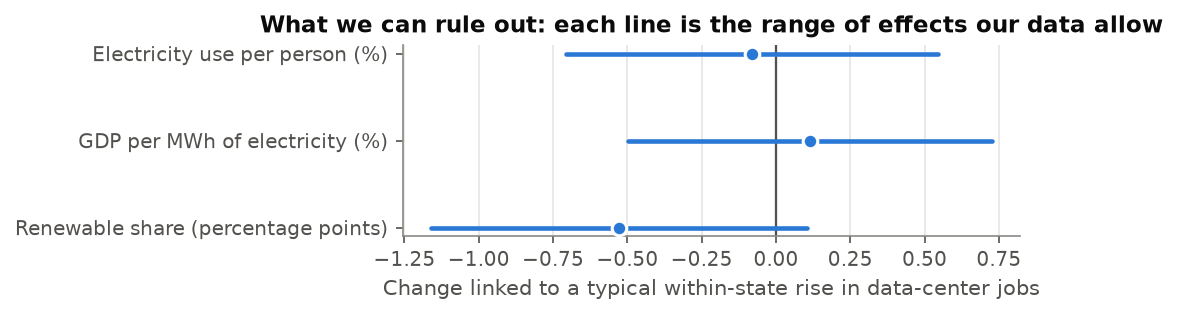

In [4]:
fig, ax = plt.subplots(figsize=(7.0, 2.2))
rows = [("Electricity use per person (%)", "ln_ec"), ("GDP per MWh of electricity (%)", "ln_ee"), ("Renewable share (percentage points)", "renew_share")]
tags = {k: f"rob_base_ai518210_lag1_ctrl4_w9901_cl-state_{k}_50s2015_2025" for _, k in rows}
coefplot(ax, [r[0] for r in rows], [raw(RO, "estimate_per_sd", tag=tags[k]) for _, k in rows],
         [raw(RO, "ci_lo_per_sd", tag=tags[k]) for _, k in rows], [raw(RO, "ci_hi_per_sd", tag=tags[k]) for _, k in rows],
         unit="Change linked to a typical within-state rise in data-center jobs")
ax.set_title("What we can rule out: each line is the range of effects our data allow")
L.fig(fig, "Estimate (dot) and 95% confidence interval (line) per one within-state standard deviation of data-center jobs. Every interval crosses zero, and each is narrow enough to rule out large effects.")

In [5]:
L.section(1, "How to read this notebook")
md(f"""Three ideas carry almost every result: a coefficient, a confidence interval and a p-value. We use one real result, the renewable share, as the running example.

**A coefficient is a slope.** It says how much the outcome tends to change when AI changes by one unit, holding the other things in the model fixed. Our AI unit is one extra data-center job per 1,000 workers. For the renewable share, the coefficient is {est(H1C, tag=h1('renew_share'))}: a state with one more data-center job per 1,000 workers tends to have a renewable share {v(H1C, 'estimate', scale=-100, tag=h1('renew_share'))} percentage points lower. *Analogy: it's the "price per pound" on a deli scale. It tells you how much one more unit adds, not the total bill.*

**A confidence interval is the range of slopes the data can't rule out.** We report 95% intervals. For the renewable share it runs from {ci(H1C, scale=100, tag=h1('renew_share'))} percentage points. *Analogy: a weather forecast that says "between 60 and 70 degrees." The narrower the range, the more useful the forecast. If the range includes zero, "no effect" is one of the possibilities the data allow.*

**A p-value measures surprise.** It's the chance of seeing a slope at least this far from zero if the true slope were zero. Small values (below 0.05 by convention) mean "this would be surprising if nothing were going on." For the renewable share, {p(H1C, tag=h1('renew_share'))}: not small enough by the usual standard. *Analogy: a friend flips a coin and gets heads 6 times out of 10. That's not surprising for a fair coin. Heads 10 times out of 10 would be. A p-value says which of those situations you're in.*

**What a p-value isn't.** It isn't the chance that the result is true, and a large p-value doesn't prove there's no effect. That's why we also report what the confidence interval rules out.

**How to read the charts.** Coefficient charts show a dot for the estimate and a line for its 95% confidence interval, with a gray vertical line at zero. If the line crosses zero, the result isn't statistically different from zero.""")

# 1. How to read this notebook

Three ideas carry almost every result: a coefficient, a confidence interval and a p-value. We use one real result, the renewable share, as the running example.

**A coefficient is a slope.** It says how much the outcome tends to change when AI (artificial intelligence) changes by one unit, holding the other things in the model fixed. Our AI unit is one extra data-center job per 1,000 workers. For the renewable share, the coefficient is −0.0101: a state with one more data-center job per 1,000 workers tends to have a renewable share 1.01 percentage points lower. *Analogy: it's the "price per pound" on a deli scale. It tells you how much one more unit adds, not the total bill.*

**A confidence interval is the range of slopes the data can't rule out.** We report 95% intervals. For the renewable share it runs from −2.2 to 0.20 percentage points. *Analogy: a weather forecast that says "between 60 and 70 degrees." The narrower the range, the more useful the forecast. If the range includes zero, "no effect" is one of the possibilities the data allow.*

**A p-value measures surprise.** It's the chance of seeing a slope at least this far from zero if the true slope were zero. Small values (below 0.05 by convention) mean "this would be surprising if nothing were going on." For the renewable share, p = 0.100: not small enough by the usual standard. *Analogy: a friend flips a coin and gets heads 6 times out of 10. That's not surprising for a fair coin. Heads 10 times out of 10 would be. A p-value says which of those situations you're in.*

**What a p-value isn't.** It isn't the chance that the result is true, and a large p-value doesn't prove there's no effect. That's why we also report what the confidence interval rules out.

**How to read the charts.** Coefficient charts show a dot for the estimate and a line for its 95% confidence interval, with a gray vertical line at zero. If the line crosses zero, the result isn't statistically different from zero.

In [6]:
L.section(2, "Key ideas, each with an analogy")
ideas = [
 ("Correlation is not causation", "Ice-cream sales and sunburns both rise in summer. Neither causes the other: the sun drives both. Two state trends can move together for the same reason. That's why everything here is an *association*."),
 ("Panel data", "We follow the same 50 states every year from 2015 to 2025, like 550 report cards: one per student per year. Seeing each state many times lets us compare a state to itself."),
 ("State fixed effects", "Compare each student to their own past grades, not Alaska to Texas. Texas always uses more electricity than Vermont for reasons unrelated to AI (size, climate, industry). State fixed effects remove each state's permanent level, so only changes within a state count."),
 ("Year fixed effects", "Grade on a curve each year. Some things hit every state at once: federal tax credits for wind and solar, COVID in 2020, falling solar prices. Year fixed effects remove each year's nationwide average, so a national trend can't masquerade as an AI effect."),
 ("Lagging AI one year", "The cause should come before the effect. We use last year's AI jobs to explain this year's outcome, so the order in time is at least right."),
 ("Lead or placebo test", "A forecast that only works after it rains isn't a forecast. If *next* year's AI jobs \"predict\" *this* year's renewables as well as last year's do, the association can't be AI acting on renewables. Something else, like where data centers choose to locate, is going on."),
 ("Clustered standard errors", "Asking the same person a question 11 times isn't 11 independent opinions. A state's 11 years are related to each other, so we treat them as one cluster. This makes our confidence intervals honestly wider."),
 ("Logs and percentage changes", "Many outcomes are in logs. A change of 0.01 in a log is about a 1% change, so log results read as percentages whatever the state's size."),
 ("A precise null", "A bathroom scale that's accurate to one pound and reads zero tells you something: there's nothing heavy on it. A broken scale that reads zero tells you nothing. A null result with a narrow confidence interval is the first kind: it rules out large effects."),
 ("Multiple testing", "Flip enough coins and some will land heads five times in a row. Run 30 tests and one or two will look significant by luck. We use the Benjamini-Hochberg correction, which raises the bar when many tests are run together, and report its q-value."),
 ("Placebo industries", "If pet-care jobs \"predict\" renewables as well as AI jobs do, the model is picking up shared growth trends, not anything specific to AI. Pet care has nothing to do with electricity."),
 ("Spatial spillovers", "Drop a stone in a pond and the ripples reach the shore. AI growth in one state might ripple into its neighbors through shared power grids and markets. Spatial models measure those ripples."),
 ("The 2023 EIA accounting change", "Imagine changing the exchange rate used to convert foreign coins into dollars. In 2023, EIA changed how SEDS converts wind and solar electricity into energy units, which made renewable energy look smaller in every year. Same wind, different yardstick."),
 ("Learning curves", "TVs and solar panels get cheaper as more are made, because factories learn and scale up. A learning rate of 20% means each doubling of total production cuts the cost by 20%."),
]
T(["Idea", "Analogy and why it matters"], [[f"**{a}**", b] for a, b in ideas], "Fourteen ideas used throughout.", widths=[22, 78])

# 2. Key ideas, each with an analogy

Idea,Analogy and why it matters
Correlation is not causation,Ice-cream sales and sunburns both rise in summer. Neither causes the other: the sun drives both. Two state trends can move together for the same reason. That's why everything here is an *association*.
Panel data,"We follow the same 50 states every year from 2015 to 2025, like 550 report cards: one per student per year. Seeing each state many times lets us compare a state to itself."
State fixed effects,"Compare each student to their own past grades, not Alaska to Texas. Texas always uses more electricity than Vermont for reasons unrelated to AI (artificial intelligence) (size, climate, industry). State fixed effects remove each state's permanent level, so only changes within a state count."
Year fixed effects,"Grade on a curve each year. Some things hit every state at once: federal tax credits for wind and solar, COVID in 2020, falling solar prices. Year fixed effects remove each year's nationwide average, so a national trend can't masquerade as an AI effect."
Lagging AI one year,"The cause should come before the effect. We use last year's AI jobs to explain this year's outcome, so the order in time is at least right."
Lead or placebo test,"A forecast that only works after it rains isn't a forecast. If *next* year's AI jobs ""predict"" *this* year's renewables as well as last year's do, the association can't be AI acting on renewables. Something else, like where data centers choose to locate, is going on."
Clustered standard errors,"Asking the same person a question 11 times isn't 11 independent opinions. A state's 11 years are related to each other, so we treat them as one cluster. This makes our confidence intervals honestly wider."
Logs and percentage changes,"Many outcomes are in logs. A change of 0.01 in a log is about a 1% change, so log results read as percentages whatever the state's size."
A precise null,A bathroom scale that's accurate to one pound and reads zero tells you something: there's nothing heavy on it. A broken scale that reads zero tells you nothing. A null result with a narrow confidence interval is the first kind: it rules out large effects.
Multiple testing,"Flip enough coins and some will land heads five times in a row. Run 30 tests and one or two will look significant by luck. We use the Benjamini-Hochberg correction, which raises the bar when many tests are run together, and report its q-value."


In [7]:
L.section(3, "The data")
md("""We built a state-by-year panel from public sources. The table lists the main variables; the full list, with every source file and its checks, is in `data/variable_registry.csv`.""")
D = [
 ("AI measure: data-center jobs", "Private jobs in data processing and hosting per 1,000 workers, last year's value", "BLS QCEW, NAICS 518210", "Core Panel", "ai_dc_per1000_lag1", "Our main AI measure"),
 ("AI job postings", "Online job ads asking for AI skills, by state", "Stanford AI Index (from vendor job-ad data)", "AI Job Postings", "postings", "Fang's AI measure"),
 ("Electricity use", "Retail electricity sales per person, in logs", "EIA sales data; BEA population", "Core Panel", "ln_ec", "Outcome: consumption"),
 ("Energy efficiency", "Real GDP per MWh of electricity, in logs", "BEA GDP; EIA sales", "Core Panel", "ln_ee", "Outcome: efficiency"),
 ("Renewable share", "Share of in-state utility-scale generation from renewables", "EIA generation by state", "Core Panel", "renew_share", "Outcome: clean power"),
 ("New renewable capacity", "Change in renewable capacity from the year before", "EIA capacity by state", "Core Panel", "new_renew_mw", "Outcome: build-out"),
 ("Renewable energy use", "Renewable energy consumed in the state", "EIA SEDS", "SEDS Renewables", "re_bbtu", "Fang's outcome"),
 ("Income", "Real GDP per person, in logs", "BEA", "Core Panel", "ln_gdp_pc", "Control"),
 ("Manufacturing", "Manufacturing share of GDP", "BEA", "Core Panel", "manuf_share", "Control"),
 ("Electricity price", "Average retail price", "EIA", "Core Panel", "price_c_kwh", "Control"),
 ("Population growth", "Growth from the year before", "BEA", "Core Panel", "pop_growth", "Control"),
 ("Tech jobs", "Computer-systems-design jobs as a share of all jobs", "BLS QCEW, NAICS 5415", "Core Panel", "tech_share", "Zhang's channel (mediator)"),
 ("Economic density", "Nonfarm GDP per square mile, in logs", "BEA; Census Bureau land area", "Core Panel", "ln_ea", "Second channel (mediator)"),
 ("Policy uncertainty", "News-based index of state economic policy uncertainty", "EPU by Baker, Davis and Levy", "EPU Annual", "epu_state", "Fang's moderator"),
 ("Renewable mandates", "Each state's RPS or CES target for the year", "LBNL RPS and CES data", "RPS Targets", "target_pct", "Control in a check"),
 ("Weather", "Heating and cooling degree days", "NOAA HDD and CDD", "NOAA Degree Days", "hdd", "Control in a check"),
 ("Federal tax credits", "Investment Tax Credit rate for solar (ITC); wind PTC similar", "CRS reports and federal law", "Drivers National", "itc_pct", "National driver"),
 ("Solar cost", "LCOE of new utility-scale solar", "LBNL Utility-Scale Solar", "Drivers National", "solar_lcoe_2025usd_mwh", "National driver; Georgia"),
 ("AI research workers", "Computer and information research scientists", "BLS OEWS", "AI Index Components", "oews_rsci", "AI index"),
]
rows = []
for name, what, src, tab, var, why in D:
    rows.append([name, what, src, s(REG, "years", tab=tab, variable=var), s(REG, "unit", tab=tab, variable=var), why])
T(["Variable", "What it measures", "Source", "Years", "Units", "Why we need it"], rows,
  "Main variables. Years and units are read from the variable registry.",
  "Also used: BTOS, the Census Bureau's survey of the share of firms using AI, as a check on our AI index; NCSES degree data, NSF R&D, ACS broadband and Epoch AI data-center data for side analyses; and Georgia PSC filings. USPTO patent data were downloaded and not used.")
md("""**Why so many sources?** No single agency measures AI, electricity and policy together, so each source answers one piece of the question: BLS counts the jobs, EIA measures the electricity, BEA measures the economy, and LBNL, CRS and NOAA supply the mandates, tax credits and weather that could otherwise be mistaken for AI. Each is the official or standard source for its piece.""")

# 3. The data

We built a state-by-year panel from public sources. The table lists the main variables; the full list, with every source file and its checks, is in `data/variable_registry.csv`.

Variable,What it measures,Source,Years,Units,Why we need it
AI (artificial intelligence) measure: data-center jobs,"Private jobs in data processing and hosting per 1,000 workers, last year's value","BLS (Bureau of Labor Statistics) QCEW (Quarterly Census of Employment and Wages), NAICS 518210 (North American Industry Classification System code 518210, Computing Infrastructure Providers, Data Processing, Web Hosting)",2015-2025,"per 1,000 workers",Our main AI measure
AI job postings,"Online job ads asking for AI skills, by state",Stanford AI Index (from vendor job-ad data),2018-2025,count,Fang's AI measure
Electricity use,"Retail electricity sales per person, in logs",EIA (U.S. Energy Information Administration) sales data; BEA (Bureau of Economic Analysis) population,2015-2025,log,Outcome: consumption
Energy efficiency,"Real GDP (gross domestic product) per MWh (megawatt-hours) of electricity, in logs",BEA GDP; EIA sales,2015-2025,log,Outcome: efficiency
Renewable share,Share of in-state utility-scale generation from renewables,EIA generation by state,2015-2025,share,Outcome: clean power
New renewable capacity,Change in renewable capacity from the year before,EIA capacity by state,2015-2025,MW (megawatts),Outcome: build-out
Renewable energy use,Renewable energy consumed in the state,EIA SEDS (State Energy Data System),2015-2024,billion Btu (British thermal units),Fang's outcome
Income,"Real GDP per person, in logs",BEA,2015-2025,log,Control
Manufacturing,Manufacturing share of GDP,BEA,2015-2025,share,Control
Electricity price,Average retail price,EIA,2015-2025,cents/kWh (kilowatt-hour),Control


**Why so many sources?** No single agency measures AI (artificial intelligence), electricity and policy together, so each source answers one piece of the question: BLS (Bureau of Labor Statistics) counts the jobs, EIA (U.S. Energy Information Administration) measures the electricity, BEA (Bureau of Economic Analysis) measures the economy, and LBNL (Lawrence Berkeley National Laboratory), CRS (Congressional Research Service) and NOAA (National Oceanic and Atmospheric Administration) supply the mandates, tax credits and weather that could otherwise be mistaken for AI. Each is the official or standard source for its piece.

In [8]:
L.section(4, "The Zhang test: our main design")
md("""Zhang et al. (2026) propose three hypotheses, which we test on U.S. states: **H1**, AI is associated with electricity use, efficiency and renewables; **H2**, the association runs through channels such as tech jobs or economic density; **H3**, AI in one place spills over to its neighbors. We use their design where U.S. data allow.""")
md("## 4.1 H1: two-way fixed effects")
md("""**The question.** When a state's data-center jobs rise faster than usual, do its electricity use, efficiency, renewable share or renewable build-out also change, compared with its own past and with the national trend?""")
md(r"""$$y_{st} = \beta\,AI_{s,t-1} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$""")
T(["Symbol", "Plain meaning"], [
 ["$y_{st}$", "The outcome in state $s$, year $t$: electricity use, efficiency, renewable share or new renewable capacity"],
 ["$AI_{s,t-1}$", "Last year's private data-center jobs per 1,000 workers (NAICS 518210)"],
 ["$\\beta$", "The number we care about: the association between AI and the outcome"],
 ["$X_{st}$, $\\gamma$", "The four controls (log real GDP per person, manufacturing share of GDP, electricity price, population growth) and their associations with the outcome"],
 ["$\\alpha_s$", "State fixed effect: each state's permanent level"],
 ["$\\delta_t$", "Year fixed effect: what hit every state in year $t$"],
 ["$\\varepsilon_{st}$", "Everything else, which we treat as noise; standard errors are clustered by state"],
], "Symbols in the H1 equation.")
md(f"""**Analogy.** A teacher wants to know whether extra tutoring helps grades. She compares each student with their own past grades (state effects), curves each year's grades (year effects), and asks whether students who got more tutoring *last* term improved more *this* term.

**What "yes" and "no" would look like.** "Yes" (Zhang's prediction): a coefficient clearly away from zero, with a confidence interval that excludes zero, and a lead test that comes back empty. "No": a coefficient near zero with a narrow interval that excludes large values.""")

# 4. The Zhang test: our main design

Zhang et al. (2026) propose three hypotheses, which we test on U.S. states: **H1**, AI (artificial intelligence) is associated with electricity use, efficiency and renewables; **H2**, the association runs through channels such as tech jobs or economic density; **H3**, AI in one place spills over to its neighbors. We use their design where U.S. data allow.

## 4.1 H1: two-way fixed effects

**The question.** When a state's data-center jobs rise faster than usual, do its electricity use, efficiency, renewable share or renewable build-out also change, compared with its own past and with the national trend?

$$y_{st} = \beta\,AI_{s,t-1} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$

Symbol,Plain meaning
$y_{st}$,"The outcome in state $s$, year $t$: electricity use, efficiency, renewable share or new renewable capacity"
"$AI_{s,t-1}$","Last year's private data-center jobs per 1,000 workers (NAICS 518210 (North American Industry Classification System code 518210, Computing Infrastructure Providers, Data Processing, Web Hosting))"
$\beta$,The number we care about: the association between AI (artificial intelligence) and the outcome
"$X_{st}$, $\gamma$","The four controls (log real GDP (gross domestic product) per person, manufacturing share of GDP, electricity price, population growth) and their associations with the outcome"
$\alpha_s$,State fixed effect: each state's permanent level
$\delta_t$,Year fixed effect: what hit every state in year $t$
$\varepsilon_{st}$,"Everything else, which we treat as noise; standard errors are clustered by state"


**Analogy.** A teacher wants to know whether extra tutoring helps grades. She compares each student with their own past grades (state effects), curves each year's grades (year effects), and asks whether students who got more tutoring *last* term improved more *this* term.

**What "yes" and "no" would look like.** "Yes" (Zhang's prediction): a coefficient clearly away from zero, with a confidence interval that excludes zero, and a lead test that comes back empty. "No": a coefficient near zero with a narrow interval that excludes large values.

Outcome,Coefficient,95% confidence interval,p-value,State-years
Electricity use per person (log),−0.00157,−0.0136 to 0.0105,p = 0.795,550
GDP (gross domestic product) per MWh (megawatt-hours) (log),0.00221,−0.00953 to 0.0139,p = 0.707,550
Renewable share (0-1),−0.0101,−0.0223 to 0.00202,p = 0.100,550
"New renewable capacity, MW (megawatts)",70.8,5.85 to 136,p = 0.033,550
"Same, per 1,000 MW of 2015 capacity",0.996,−2.98 to 4.97,p = 0.616,550


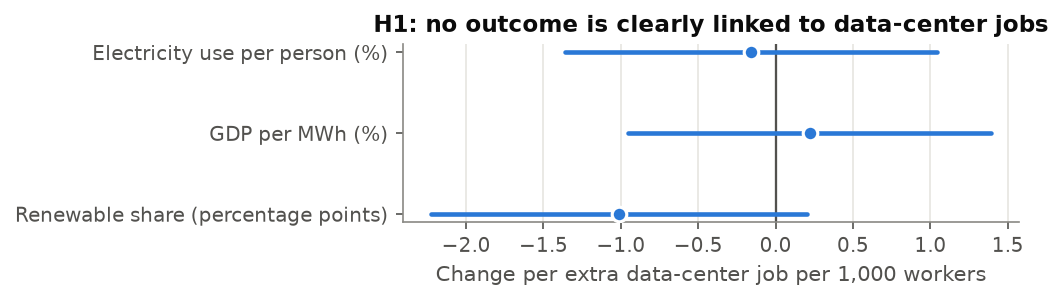

**In plain English.** States whose data-center jobs grew faster didn't use more or less electricity per person, and didn't get more or less economic output per unit of electricity, than their own trends predict. The renewable share is slightly lower (p = 0.100), and new renewable capacity is higher in raw MW (megawatts) (p = 0.033), but section 4.4 shows that neither survives a timing test.

**What we can rule out.** Per typical within-state rise in data-center jobs (one SD (standard deviation)), the 95% interval for electricity use runs from −0.71 to 0.54%, for output per MWh (megawatt-hours) from −0.50 to 0.73%, and for the renewable share from −1.2 to 0.11 percentage points. So we can rule out, for example, a 1% rise in electricity use per person from a typical swing in data-center jobs.

In [9]:
outs = [("Electricity use per person (log)", "ln_ec", H1C, h1("ln_ec")), ("GDP per MWh (log)", "ln_ee", H1C, h1("ln_ee")),
        ("Renewable share (0-1)", "renew_share", H1C, h1("renew_share")), ("New renewable capacity, MW", "new_renew_mw", H1X, NRW),
        ("Same, per 1,000 MW of 2015 capacity", "per1000", H1X, NRW1000)]
T(["Outcome", "Coefficient", "95% confidence interval", "p-value", "State-years"],
  [[lab, est(src, tag=tg), ci(src, sig=3, tag=tg), p(src, tag=tg), n(src, "N", tag=tg)] for lab, _, src, tg in outs],
  "H1 results: last year's data-center jobs per 1,000 workers, state and year fixed effects, four controls, standard errors clustered by state, 50 states, 2015-2025.")
fig, ax = plt.subplots(figsize=(7.0, 2.11))
lab3 = ["Electricity use per person (%)", "GDP per MWh (%)", "Renewable share (percentage points)"]
tg3 = [h1("ln_ec"), h1("ln_ee"), h1("renew_share")]
coefplot(ax, lab3, [100 * raw(H1C, "estimate", tag=t) for t in tg3], [100 * raw(H1C, "ci_lo", tag=t) for t in tg3],
         [100 * raw(H1C, "ci_hi", tag=t) for t in tg3], unit="Change per extra data-center job per 1,000 workers")
ax.set_title("H1: no outcome is clearly linked to data-center jobs")
L.fig(fig, "H1 coefficients times 100, with 95% confidence intervals. Log outcomes read as percent; the renewable share reads as percentage points.")
md(f"""**In plain English.** States whose data-center jobs grew faster didn't use more or less electricity per person, and didn't get more or less economic output per unit of electricity, than their own trends predict. The renewable share is slightly lower ({p(H1C, tag=h1('renew_share'))}), and new renewable capacity is higher in raw MW ({p(H1X, tag=NRW)}), but section 4.4 shows that neither survives a timing test.""")
md(f"""**What we can rule out.** Per typical within-state rise in data-center jobs (one SD), the 95% interval for electricity use runs from {ci(RO, lo='ci_lo_per_sd', hi='ci_hi_per_sd', tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025')}%, for output per MWh from {ci(RO, lo='ci_lo_per_sd', hi='ci_hi_per_sd', tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ee_50s2015_2025')}%, and for the renewable share from {ci(RO, lo='ci_lo_per_sd', hi='ci_hi_per_sd', tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2025')} percentage points. So we can rule out, for example, a 1% rise in electricity use per person from a typical swing in data-center jobs.""")

In [10]:
md("## 4.2 H2: mediation (is there a channel?)")
md("""**The question.** If AI were associated with the outcomes, would it be *through* something else, such as more tech jobs (Zhang's channel), a combined AI-and-tech index, or denser economic activity?""")
md(r"""$$M_{st} = a\,AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + u_{st}$$
$$y_{st} = c'\,AI_{s,t-1} + b\,M_{st} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$

$$\text{indirect association} = a \times b$$""")
T(["Symbol", "Plain meaning"], [
 ["$M_{st}$", "The proposed channel (mediator): tech-job share, the AI-tech coupling index, or economic density"],
 ["$a$", "Is AI associated with the channel? (the first link)"],
 ["$b$", "Is the channel associated with the outcome, holding AI fixed? (the second link)"],
 ["$c'$", "What's left of the AI association after the channel is accounted for"],
 ["$a \\times b$", "The part of the association that runs through the channel"],
], "Symbols in the mediation equations.")
md("""**Analogy.** A bucket brigade passes water from a well to a fire. Water reaches the fire through the brigade only if both handoffs work: well to person ($a$) and person to fire ($b$). If either link is broken, nothing flows through that path.

**What "yes" and "no" would look like.** "Yes": both links are clearly nonzero and the product $a \\times b$ has a confidence interval that excludes zero. "No": the first link fails, so nothing can flow through it.""")

## 4.2 H2: mediation (is there a channel?)

**The question.** If AI were associated with the outcomes, would it be *through* something else, such as more tech jobs (Zhang's channel), a combined AI-and-tech index, or denser economic activity?

$$M_{st} = a\,AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + u_{st}$$
$$y_{st} = c'\,AI_{s,t-1} + b\,M_{st} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$

$$\text{indirect association} = a \times b$$

Symbol,Plain meaning
$M_{st}$,"The proposed channel (mediator): tech-job share, the AI (artificial intelligence)-tech coupling index, or economic density"
$a$,Is AI associated with the channel? (the first link)
$b$,"Is the channel associated with the outcome, holding AI fixed? (the second link)"
$c'$,What's left of the AI association after the channel is accounted for
$a \times b$,The part of the association that runs through the channel


**Analogy.** A bucket brigade passes water from a well to a fire. Water reaches the fire through the brigade only if both handoffs work: well to person ($a$) and person to fire ($b$). If either link is broken, nothing flows through that path.

**What "yes" and "no" would look like.** "Yes": both links are clearly nonzero and the product $a \times b$ has a confidence interval that excludes zero. "No": the first link fails, so nothing can flow through it.

Channel,First link: AI (artificial intelligence) to channel ($a$),p-value,Comment
Tech-job share (Zhang's channel),−0.000157,p = 0.454,Fails: AI isn't associated with the tech-job share
AI-tech coupling index,0.0416,p < 0.001,Positive by construction: the index is built from AI itself
Economic density,−0.00336,p = 0.296,Fails: income already absorbs it


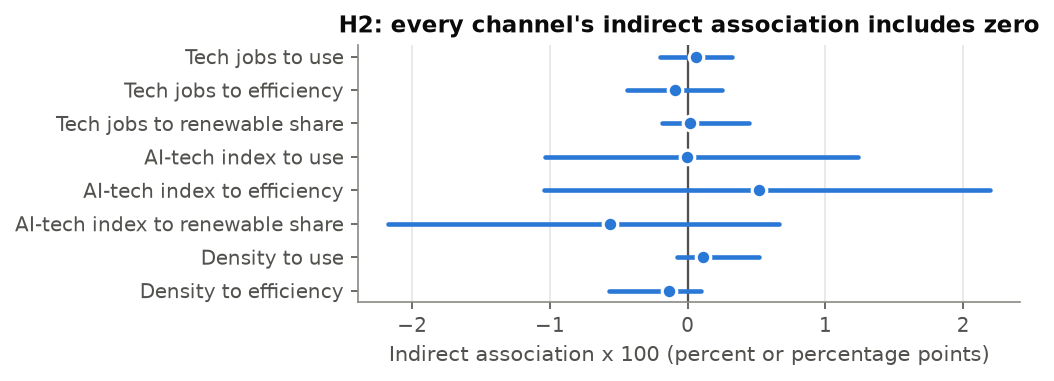

**In plain English.** Data-center jobs aren't associated with tech jobs in general (p = 0.454), so Zhang's channel has nothing to carry. The coupling index looks linked only because it's built from the AI measure itself. Every indirect association has a confidence interval that includes zero.

**What we can rule out.** For the tech-job channel, the first link's interval runs from −0.00057 to 0.00026: a typical swing in data-center jobs moves the tech-job share by far less than a hundredth of a percentage point.

In [11]:
fs = [("Tech-job share (Zhang's channel)", "h2a_med_ai518210_lag1_M-techshare_ctrl4_w9901_cl-state_renew_share_50s2015_2025_eq-a"),
      ("AI-tech coupling index", "h2a_med_ai518210_lag1_M-hma_ctrl4_w9901_cl-state_renew_share_50s2015_2025_eq-a"),
      ("Economic density", "h2b_med_ai518210_lag1_M-lnea_ctrl4_w9901_cl-state_renew_share_50s2015_2025_eq-a")]
T(["Channel", "First link: AI to channel ($a$)", "p-value", "Comment"],
  [[fs[0][0], est(H2, tag=fs[0][1]), p(H2, tag=fs[0][1]), "Fails: AI isn't associated with the tech-job share"],
   [fs[1][0], est(H2, tag=fs[1][1]), p(H2, tag=fs[1][1]), "Positive by construction: the index is built from AI itself"],
   [fs[2][0], est(H2, tag=fs[2][1]), p(H2, tag=fs[2][1]), "Fails: income already absorbs it"]],
  "H2 first links, with the Sobel test range across all 9 channel-outcome pairs below.",
  f"Sobel p-values across the {n(MED, 'n', tag='h2_sobel_summary')} pairs run from {v(MED, 'min_p', dec=3, tag='h2_sobel_summary')} to {v(MED, 'max_p', dec=3, tag='h2_sobel_summary')}. Bootstrap: 999 cluster resamples.")
pairs = [(m, y) for m in ["techshare", "hma"] for y in ["ln_ec", "ln_ee", "renew_share"]] + [("lnea", y) for y in ["ln_ec", "ln_ee"]]
lab = {"techshare": "Tech jobs", "hma": "AI-tech index", "lnea": "Density", "ln_ec": "use", "ln_ee": "efficiency", "renew_share": "renewable share"}
def btag(m, y):
    hb = "h2b" if m == "lnea" else "h2a"; mm = {"techshare": "techshare", "hma": "hma", "lnea": "lnea"}[m]
    return f"{hb}_med_ai518210_lag1_M-{mm}_ctrl4_w9901_cl-state_{y}_50s2015_2025_indirect-bootstrap"
fig, ax = plt.subplots(figsize=(7.0, 2.64))
coefplot(ax, [f"{lab[m]} to {lab[y]}" for m, y in pairs], [100 * raw(H2, "estimate", tag=btag(m, y)) for m, y in pairs],
         [100 * raw(H2, "ci_lo", tag=btag(m, y)) for m, y in pairs], [100 * raw(H2, "ci_hi", tag=btag(m, y)) for m, y in pairs],
         unit="Indirect association x 100 (percent or percentage points)")
ax.set_title("H2: every channel's indirect association includes zero")
L.fig(fig, "Indirect association (a times b) for each channel and outcome, with 95% cluster-bootstrap intervals.")
md(f"""**In plain English.** Data-center jobs aren't associated with tech jobs in general ({p(H2, tag=fs[0][1])}), so Zhang's channel has nothing to carry. The coupling index looks linked only because it's built from the AI measure itself. Every indirect association has a confidence interval that includes zero.

**What we can rule out.** For the tech-job channel, the first link's interval runs from {ci(H2, sig=2, tag=fs[0][1])}: a typical swing in data-center jobs moves the tech-job share by far less than a hundredth of a percentage point.""")

In [12]:
md("## 4.3 H3: spatial spillovers")
md("""**The question.** Do states cluster by renewable share, and is AI growth in *neighboring* states associated with a state's own outcomes?""")
md(r"""**Moran's I** (do neighbors look alike?):
$$I = \frac{N}{\sum_{i}\sum_{j} w_{ij}} \cdot \frac{\sum_i \sum_j w_{ij}(y_i-\bar y)(y_j-\bar y)}{\sum_i (y_i-\bar y)^2}$$

**SLX model** (neighbors' AI on the right-hand side), and **SDM** (also neighbors' outcomes):
$$y_{st} = \rho \sum_j w_{sj}\, y_{jt} + \beta\,AI_{s,t-1} + \theta \sum_j w_{sj}\,AI_{j,t-1} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$
The SLX model is the same equation with $\rho = 0$.""")
T(["Symbol", "Plain meaning"], [
 ["$w_{ij}$", "How close states $i$ and $j$ are. Main version: one over the distance between state centers, all 50 states; check: shared border, 48 contiguous states. Each state's weights sum to one"],
 ["$\\sum_j w_{sj} AI_{j,t-1}$", "The average AI of state $s$'s neighbors, closer ones counting more"],
 ["$\\theta$", "Association with neighbors' AI"],
 ["$\\rho$", "How much a state's outcome moves with its neighbors' outcomes (the echo)"],
 ["Direct effect", "Association of a state's own AI with its own outcome, including echoes back from neighbors"],
 ["Indirect effect", "Association of all other states' AI with this state's outcome: the spillover"],
 ["Total effect", "Direct plus indirect"],
], "Symbols in the spatial models.")
md("""**Analogy.** Drop a stone in a pond (AI growth in one state). The direct effect is the splash where it lands; the indirect effect is the ripples reaching other shores; $\\rho$ is how much the ripples bounce back and forth.

**What "yes" and "no" would look like.** "Yes": a clearly nonzero indirect effect that comes from neighbors' *past* AI, not their *future* AI. "No": no indirect effect, or one that future AI explains as well.""")

## 4.3 H3: spatial spillovers

**The question.** Do states cluster by renewable share, and is AI growth in *neighboring* states associated with a state's own outcomes?

**Moran's I** (do neighbors look alike?):
$$I = \frac{N}{\sum_{i}\sum_{j} w_{ij}} \cdot \frac{\sum_i \sum_j w_{ij}(y_i-\bar y)(y_j-\bar y)}{\sum_i (y_i-\bar y)^2}$$

**SLX (spatial lag of X model) model** (neighbors' AI on the right-hand side), and **SDM (spatial Durbin model)** (also neighbors' outcomes):
$$y_{st} = \rho \sum_j w_{sj}\, y_{jt} + \beta\,AI_{s,t-1} + \theta \sum_j w_{sj}\,AI_{j,t-1} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$
The SLX model is the same equation with $\rho = 0$.

Symbol,Plain meaning
$w_{ij}$,"How close states $i$ and $j$ are. Main version: one over the distance between state centers, all 50 states; check: shared border, 48 contiguous states. Each state's weights sum to one"
"$\sum_j w_{sj} AI_{j,t-1}$","The average AI (artificial intelligence) of state $s$'s neighbors, closer ones counting more"
$\theta$,Association with neighbors' AI
$\rho$,How much a state's outcome moves with its neighbors' outcomes (the echo)
Direct effect,"Association of a state's own AI with its own outcome, including echoes back from neighbors"
Indirect effect,Association of all other states' AI with this state's outcome: the spillover
Total effect,Direct plus indirect


**Analogy.** Drop a stone in a pond (AI growth in one state). The direct effect is the splash where it lands; the indirect effect is the ripples reaching other shores; $\rho$ is how much the ripples bounce back and forth.

**What "yes" and "no" would look like.** "Yes": a clearly nonzero indirect effect that comes from neighbors' *past* AI, not their *future* AI. "No": no indirect effect, or one that future AI explains as well.

Test (renewable share),Estimate,95% interval or note,p-value
"Moran's I, lowest year",0.0941 (2015),States with similar shares cluster,p = 0.001
"Moran's I, highest year",0.157 (2025),Clustering rises over time,p = 0.001
SLX (spatial lag of X model): own AI (artificial intelligence),−0.0136,Clustered by state,p = 0.014
SLX: neighbors' AI,−0.0551,Clustered by state,p = 0.117
SDM: echo,0.617,"Main spec, inverse distance",
SDM: direct,−0.0155,−0.024 to −0.0073,p < 0.001
SDM: indirect (spillover),−0.161,−0.34 to −0.035,p = 0.035
SDM: total,−0.177,−0.36 to −0.046,p = 0.026
"Timing, border neighbors: past AI",0.00977,"2015-2023, lag and lead together",p = 0.583
"Timing, border neighbors: future AI",−0.0406,"2015-2023, lag and lead together",p = 0.027


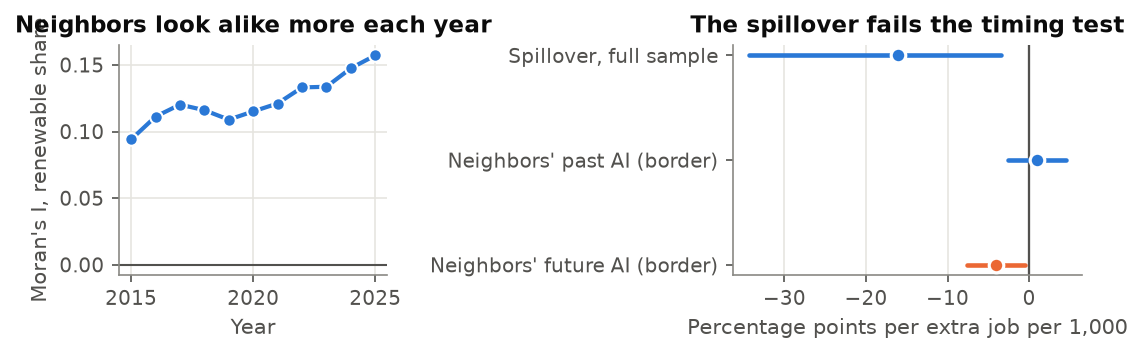

**In plain English.** Neighboring states do have similar renewable shares, and the similarity grows over time. The full-sample model finds a negative spillover (p = 0.035). But when we add neighbors' *future* AI, it's the future AI that carries the association with border weights (p = 0.027), not the past (p = 0.583). A ripple that arrives before the stone is dropped isn't a ripple, so H3 is not supported.

**What we can rule out.** Per typical within-state swing in neighbors' AI, the full-sample spillover is −1.39 percentage points; because it can't be separated from reverse timing, we don't read it as a spillover at all.

In [13]:
yrs = sorted(tbl(MOR).query("variable=='renew_share' and W_version=='invdist50' and type=='raw'").year)
Ivals = {y: raw(MOR, "moran_I", variable="renew_share", year=y, W_version="invdist50", type="raw") for y in yrs}
ylo, yhi = min(Ivals, key=Ivals.get), max(Ivals, key=Ivals.get)
pmax_y = max(yrs, key=lambda y: raw(MOR, "p_value", variable="renew_share", year=y, W_version="invdist50", type="raw"))
slxf = dict(outcome="renew_share", W_version="invdist50")
B_LEAD = "h3_slx-placebo-d_both_ai518210_lead1lag1_ctrl4_w9901_cl-state_renew_share_48s2015_2023_border48_theta_lead"
B_LAG = "h3_slx-placebo-d_both_ai518210_lead1lag1_ctrl4_w9901_cl-state_renew_share_48s2015_2023_border48_theta_lag"
I_LEAD = "h3_slx-placebo-d_both_ai518210_lead1lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2023_invdist50_theta_lead"
I_LAG = "h3_slx-placebo-d_both_ai518210_lead1lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2023_invdist50_theta_lag"
T(["Test (renewable share)", "Estimate", "95% interval or note", "p-value"], [
 ["Moran's I, lowest year", f"{v(MOR, 'moran_I', variable='renew_share', year=ylo, W_version='invdist50', type='raw')} ({ylo})", "States with similar shares cluster", p(MOR, 'p_value', variable='renew_share', year=ylo, W_version='invdist50', type='raw')],
 ["Moran's I, highest year", f"{v(MOR, 'moran_I', variable='renew_share', year=yhi, W_version='invdist50', type='raw')} ({yhi})", "Clustering rises over time", p(MOR, 'p_value', variable='renew_share', year=yhi, W_version='invdist50', type='raw')],
 ["SLX: own AI", v(SLXF, 'b1', **slxf), "Clustered by state", p(SLXF, 'p_b1', **slxf)],
 ["SLX: neighbors' AI", v(SLXF, 'theta1', **slxf), "Clustered by state", p(SLXF, 'p_theta1', **slxf)],
 ["SDM: echo", v(SDMI, 'rho', tag=SDM, effect='direct'), "Main spec, inverse distance", ""],
 ["SDM: direct", v(SDMI, 'plugin', tag=SDM, effect='direct'), ci(SDMI, sig=2, tag=SDM, effect='direct'), p(SDMI, 'p', tag=SDM, effect='direct')],
 ["SDM: indirect (spillover)", v(SDMI, 'plugin', tag=SDM, effect='indirect'), ci(SDMI, sig=2, tag=SDM, effect='indirect'), p(SDMI, 'p', tag=SDM, effect='indirect')],
 ["SDM: total", v(SDMI, 'plugin', tag=SDM, effect='total'), ci(SDMI, sig=2, tag=SDM, effect='total'), p(SDMI, 'p', tag=SDM, effect='total')],
 ["Timing, border neighbors: past AI", v(PSLX, 'estimate', tag=B_LAG), "2015-2023, lag and lead together", p(PSLX, tag=B_LAG)],
 ["Timing, border neighbors: future AI", v(PSLX, 'estimate', tag=B_LEAD), "2015-2023, lag and lead together", p(PSLX, tag=B_LEAD)],
 ["Timing, inverse distance: past AI", v(PSLX, 'estimate', tag=I_LAG), "2015-2023, lag and lead together", p(PSLX, tag=I_LAG)],
 ["Timing, inverse distance: future AI", v(PSLX, 'estimate', tag=I_LEAD), "2015-2023, lag and lead together", p(PSLX, tag=I_LEAD)],
], "H3 results for the renewable share (0-1 scale). SDM is the main specification (maximum likelihood, inverse-distance weights).")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.46), gridspec_kw=dict(width_ratios=[1, 1.3]))
a1.plot(yrs, [Ivals[y] for y in yrs], "-o", color=BLUE, lw=2, ms=6, mec="white")
a1.axhline(0, color=INK2, lw=1); a1.set_title("Neighbors look alike more each year"); a1.set_ylabel("Moran's I, renewable share"); a1.set_xlabel("Year")
labs = ["Spillover, full sample", "Neighbors' past AI (border)", "Neighbors' future AI (border)"]
e = [100 * raw(SDMI, "plugin", tag=SDM, effect="indirect"), 100 * raw(PSLX, "estimate", tag=B_LAG), 100 * raw(PSLX, "estimate", tag=B_LEAD)]
lo = [100 * raw(SDMI, "ci_lo", tag=SDM, effect="indirect"), 100 * raw(PSLX, "ci_lo", tag=B_LAG), 100 * raw(PSLX, "ci_lo", tag=B_LEAD)]
hi = [100 * raw(SDMI, "ci_hi", tag=SDM, effect="indirect"), 100 * raw(PSLX, "ci_hi", tag=B_LAG), 100 * raw(PSLX, "ci_hi", tag=B_LEAD)]
coefplot(a2, labs, e, lo, hi, colors=[BLUE, BLUE, ORANGE], unit="Percentage points per extra job per 1,000")
a2.set_title("The spillover fails the timing test")
L.fig(fig, "Left: Moran's I for the renewable share each year. Right: the full-sample spillover (spatial Durbin model), and on 2015-2023 the association with neighbors' past and future AI (border weights), with 95% intervals.")
md(f"""**In plain English.** Neighboring states do have similar renewable shares, and the similarity grows over time. The full-sample model finds a negative spillover ({p(SDMI, 'p', tag=SDM, effect='indirect')}). But when we add neighbors' *future* AI, it's the future AI that carries the association with border weights ({p(PSLX, tag=B_LEAD)}), not the past ({p(PSLX, tag=B_LAG)}). A ripple that arrives before the stone is dropped isn't a ripple, so H3 is not supported.

**What we can rule out.** Per typical within-state swing in neighbors' AI, the full-sample spillover is {v(I1SD, 'indirect_per_1sd', scale=100, W_version='invdist50', estimator='ML')} percentage points; because it can't be separated from reverse timing, we don't read it as a spillover at all.""")

In [14]:
md("## 4.4 Robustness: lead, lags, long difference, state trends")
md("""**The question.** Do the H1 results hold when we change how time enters the model?""")
md(r"""$$y_{st} = \beta_{lag}\,AI_{s,t-1} + \beta_{lead}\,AI_{s,t+1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$""")
T(["Symbol or variant", "Plain meaning"], [
 ["$\\beta_{lead}$, $AI_{s,t+1}$", "Next year's AI: the lead or placebo. It shouldn't matter if AI acts on outcomes"],
 ["$\\beta_{lag}$", "Last year's AI, estimated alongside the lead"],
 ["Distributed lags", "AI one, two and three years back together (2017-2025), and their sum"],
 ["Long difference", "Change in AI from 2014 to 2024 against the change in the outcome from 2015 to 2025, one row per state"],
 ["State trends", "Each state gets its own straight-line trend, so steady state-specific growth can't masquerade as AI"],
], "Symbols and variants in the robustness checks. All other symbols are as in H1.")
md("""**Analogy.** A rooster crows before sunrise, but nobody thinks the rooster raises the sun. Checking whether *next* year's AI "explains" this year's outcome is checking for roosters.

**What "yes" and "no" would look like.** A real association: last year's AI matters and next year's doesn't. A timing problem: next year's AI matters as much or more.""")

## 4.4 Robustness: lead, lags, long difference, state trends

**The question.** Do the H1 results hold when we change how time enters the model?

$$y_{st} = \beta_{lag}\,AI_{s,t-1} + \beta_{lead}\,AI_{s,t+1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$

Symbol or variant,Plain meaning
"$\beta_{lead}$, $AI_{s,t+1}$",Next year's AI (artificial intelligence): the lead or placebo. It shouldn't matter if AI acts on outcomes
$\beta_{lag}$,"Last year's AI, estimated alongside the lead"
Distributed lags,"AI one, two and three years back together (2017-2025), and their sum"
Long difference,"Change in AI from 2014 to 2024 against the change in the outcome from 2015 to 2025, one row per state"
State trends,"Each state gets its own straight-line trend, so steady state-specific growth can't masquerade as AI"


**Analogy.** A rooster crows before sunrise, but nobody thinks the rooster raises the sun. Checking whether *next* year's AI "explains" this year's outcome is checking for roosters.

**What "yes" and "no" would look like.** A real association: last year's AI matters and next year's doesn't. A timing problem: next year's AI matters as much or more.

Version (renewable share),Coefficient (percentage points),95% interval,p-value
Main H1 (last year's AI (artificial intelligence)),−1.01,−2.2 to 0.20,p = 0.100
Next year's AI alone (lead),−1.97,−3.4 to −0.59,p = 0.006
Both together: last year's AI,0.146,−1.2 to 1.5,p = 0.827
Both together: next year's AI,−2.10,−3.6 to −0.59,p = 0.007
"Distributed lags, sum of 3 years",−0.950,−2.2 to 0.27,p = 0.124
"Long difference, 50 states",−1.37,−3.1 to 0.32,p = 0.110
Drop 2020,−1.08,−2.3 to 0.16,p = 0.087
Drop Virginia,−1.01,−2.2 to 0.22,p = 0.104
Control for RPS (Renewable Portfolio Standard) targets,−1.03,−2.3 to 0.20,p = 0.099
All-ownership AI jobs,−0.996,−2.2 to 0.20,p = 0.102


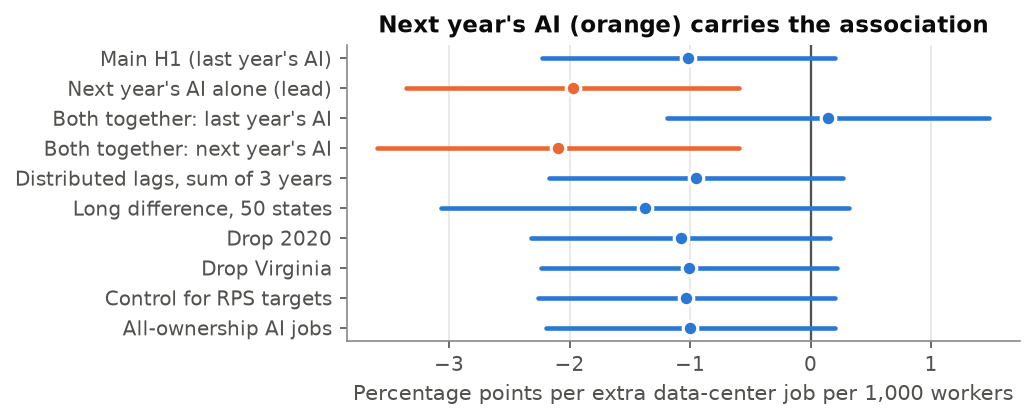

**In plain English.** Every version gives about the same small negative number, but the lead test breaks the story: next year's AI is associated with this year's renewable share (p = 0.006), and with both in the model, last year's AI drops to about zero (0.146 points, p = 0.827). The negative association reflects where and when data-center jobs grow, not AI lowering the share. New renewable capacity has the same problem: its lead is also positive (86.8 MW, p = 0.028).

Two more checks change nothing. Holding the Gavins Point dam in Nebraska gives 71.0 MW for new capacity. Adding NOAA (National Oceanic and Atmospheric Administration) HDD (heating degree days) and CDD (cooling degree days) to the electricity-use model on the 48 contiguous states gives −0.00211 (p = 0.711), against −0.000888 without them.

**What we can rule out.** With both lead and lag in the model, the interval for last year's AI is −1.2 to 1.5 percentage points per extra job per 1,000 workers.

In [15]:
rs = "renew_share"
rob_rows = [
 ("Main H1 (last year's AI)", H1C, dict(tag=h1(rs))),
 ("Next year's AI alone (lead)", ROB, dict(tag=lead(rs))),
 ("Both together: last year's AI", ROB, dict(tag=jlag(rs))),
 ("Both together: next year's AI", ROB, dict(tag=jlead(rs))),
 ("Distributed lags, sum of 3 years", ROB, dict(tag="dyn_twfe_ai518210_lag1to3sum_ctrl4_w9901_cl-state_renew_share_50s2017_2025")),
 ("Long difference, 50 states", ROB, dict(tag="dyn_longdiff-fixed_ai518210_longdiff_ctrl4_w9901_hc1_renew_share_50s2015_2025")),
 ("Drop 2020", ROB, dict(tag="rob_drop2020_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2025no2020")),
 ("Drop Virginia", ROB, dict(tag="rob_dropVA_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_49s2015_2025noVA")),
 ("Control for RPS targets", ROB, dict(tag="rob_rps_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2025")),
 ("All-ownership AI jobs", ROB, dict(tag="rob_allown_ai518210allown_lag1_ctrl4_w9901_cl-state_renew_share_50s2015_2025")),
]
rr = [[lab, v(src, "estimate", scale=100, **f), ci(src, scale=100, **f), p(src, **f)] for lab, src, f in rob_rows]
rr.append(["With state trends", v(STR, "estimate_twfe_trend", scale=100, block="p2h1", ai_measure="ai518210", outcome=rs), "", p(STR, "pval_twfe_trend", block="p2h1", ai_measure="ai518210", outcome=rs)])
T(["Version (renewable share)", "Coefficient (percentage points)", "95% interval", "p-value"], rr,
  "Robustness of the renewable-share association, per extra data-center job per 1,000 workers.")
fig, ax = plt.subplots(figsize=(7.0, 2.9))
labs = [r[0] for r in rob_rows]
coefplot(ax, labs, [100 * raw(src, "estimate", **f) for _, src, f in rob_rows], [100 * raw(src, "ci_lo", **f) for _, src, f in rob_rows],
         [100 * raw(src, "ci_hi", **f) for _, src, f in rob_rows], colors=[BLUE, ORANGE, BLUE, ORANGE] + [BLUE] * 6,
         unit="Percentage points per extra data-center job per 1,000 workers")
ax.set_title("Next year's AI (orange) carries the association")
L.fig(fig, "Renewable-share coefficient under each version, with 95% intervals. Orange rows use next year's AI.")
md(f"""**In plain English.** Every version gives about the same small negative number, but the lead test breaks the story: next year's AI is associated with this year's renewable share ({p(ROB, tag=lead(rs))}), and with both in the model, last year's AI drops to about zero ({v(ROB, 'estimate', scale=100, tag=jlag(rs))} points, {p(ROB, tag=jlag(rs))}). The negative association reflects where and when data-center jobs grow, not AI lowering the share. New renewable capacity has the same problem: its lead is also positive ({est(ROB, tag=lead('new_renew_mw'))} MW, {p(ROB, tag=lead('new_renew_mw'))}).

Two more checks change nothing. Holding the Gavins Point dam in Nebraska gives {est(ROB, tag='rob_gavins-ne_ai518210_lag1_ctrl4_w9901_cl-state_new_renew_mw_50s2015_2025')} MW for new capacity. Adding NOAA HDD and CDD to the electricity-use model on the 48 contiguous states gives {est(WX, tag='rob_weather-hddcdd_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_48s2015_2025_ai_dc_per1000_lag1')} ({p(WX, tag='rob_weather-hddcdd_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_48s2015_2025_ai_dc_per1000_lag1')}), against {est(WX, tag='rob_weather-base48_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_48s2015_2025_ai_dc_per1000_lag1')} without them.

**What we can rule out.** With both lead and lag in the model, the interval for last year's AI is {ci(ROB, scale=100, tag=jlag(rs))} percentage points per extra job per 1,000 workers.""")

In [16]:
md("## 4.5 Instrumental variable: why it was uninformative")
md("""**The question.** Can we isolate AI growth that comes from national industry growth rather than from local conditions, to get closer to cause and effect?""")
md(r"""$$\text{First stage: } AI_{s,t-1} = \pi\, Z_{s,t-1} + \text{controls} + \alpha_s + \delta_t + u_{st}$$
$$Z_{s,t} = \text{share}_{s,2015} \times \text{national growth}_t$$
$$\text{Second stage: } y_{st} = \beta_{IV}\, \widehat{AI}_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$""")
T(["Symbol", "Plain meaning"], [
 ["$Z_{s,t}$", "The instrument: the state's 2015 share of national data-center jobs times national data-center growth (a shift-share)"],
 ["$\\pi$", "How strongly the instrument predicts actual AI jobs"],
 ["$\\widehat{AI}$", "The part of AI that the instrument predicts"],
 ["$\\beta_{IV}$", "The association using only that predicted part"],
 ["First-stage F", "Instrument strength; the usual rule of thumb asks for at least 10"],
], "Symbols in the IV model.")
md("""**Analogy.** To learn whether fertilizer helps crops, you'd like fertilizer handed out by coin flip. The instrument is a stand-in coin flip. If the "coin" barely changes who gets fertilizer, it can't tell you anything.

**What "yes" and "no" would look like.** A useful instrument has a first-stage F above 10 and a reasonably tight second-stage interval. A weak one has F below 10 and a second stage too wide to read.""")

## 4.5 Instrumental variable: why it was uninformative

**The question.** Can we isolate AI growth that comes from national industry growth rather than from local conditions, to get closer to cause and effect?

$$\text{First stage: } AI_{s,t-1} = \pi\, Z_{s,t-1} + \text{controls} + \alpha_s + \delta_t + u_{st}$$
$$Z_{s,t} = \text{share}_{s,2015} \times \text{national growth}_t$$
$$\text{Second stage: } y_{st} = \beta_{IV}\, \widehat{AI}_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$

Symbol,Plain meaning
"$Z_{s,t}$",The instrument: the state's 2015 share of national data-center jobs times national data-center growth (a shift-share)
$\pi$,How strongly the instrument predicts actual AI (artificial intelligence) jobs
$\widehat{AI}$,The part of AI that the instrument predicts
$\beta_{IV}$,The association using only that predicted part
First-stage F,Instrument strength; the usual rule of thumb asks for at least 10


**Analogy.** To learn whether fertilizer helps crops, you'd like fertilizer handed out by coin flip. The instrument is a stand-in coin flip. If the "coin" barely changes who gets fertilizer, it can't tell you anything.

**What "yes" and "no" would look like.** A useful instrument has a first-stage F above 10 and a reasonably tight second-stage interval. A weak one has F below 10 and a second stage too wide to read.

Quantity,Estimate,95% interval,p-value
First-stage F (instrument strength),2.81,Needs 10 or more,
"Renewable share, ordinary regression",−0.0101,−0.022 to 0.0020,p = 0.100
"Renewable share, IV",0.112,−0.075 to 0.30,p = 0.236
"Electricity use, IV",0.0392,−0.11 to 0.19,p = 0.596


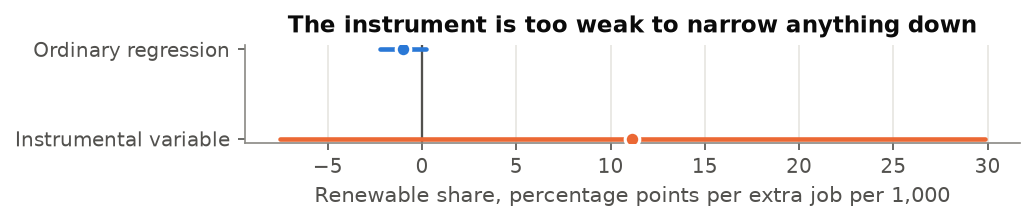

**In plain English.** The instrument barely predicts actual data-center jobs (F = 2.81, well below 10), so the IV (instrumental variable) estimate's interval is many times wider than the ordinary one. It can't confirm or reject anything, and we treat it as uninformative.

**What we can rule out.** Nothing beyond what the ordinary regression already rules out.

In [17]:
IVB = "stretch_iv_base2015_ai518210_lag1_ctrl4_w9901_cl-state_"
T(["Quantity", "Estimate", "95% interval", "p-value"], [
 ["First-stage F (instrument strength)", v(ST, "estimate", tag=IVB + "first_stage_50s2015_2025_KP_F"), "Needs 10 or more", ""],
 ["Renewable share, ordinary regression", est(ST, tag=IVB + "renew_share_50s2015_2025_ols_same_sample"), ci(ST, sig=2, tag=IVB + "renew_share_50s2015_2025_ols_same_sample"), p(ST, tag=IVB + "renew_share_50s2015_2025_ols_same_sample")],
 ["Renewable share, IV", est(ST, tag=IVB + "renew_share_50s2015_2025_iv_second_stage"), ci(ST, sig=2, tag=IVB + "renew_share_50s2015_2025_iv_second_stage"), p(ST, tag=IVB + "renew_share_50s2015_2025_iv_second_stage")],
 ["Electricity use, IV", est(ST, tag=IVB + "ln_ec_50s2015_2025_iv_second_stage"), ci(ST, sig=2, tag=IVB + "ln_ec_50s2015_2025_iv_second_stage"), p(ST, tag=IVB + "ln_ec_50s2015_2025_iv_second_stage")],
], "Shift-share IV, 2015 base shares, clustered by state.")
fig, ax = plt.subplots(figsize=(7.0, 1.58))
tg = [IVB + "renew_share_50s2015_2025_ols_same_sample", IVB + "renew_share_50s2015_2025_iv_second_stage"]
coefplot(ax, ["Ordinary regression", "Instrumental variable"], [100 * raw(ST, "estimate", tag=t) for t in tg],
         [100 * raw(ST, "ci_lo", tag=t) for t in tg], [100 * raw(ST, "ci_hi", tag=t) for t in tg], colors=[BLUE, ORANGE],
         unit="Renewable share, percentage points per extra job per 1,000")
ax.set_title("The instrument is too weak to narrow anything down")
L.fig(fig, "Renewable share: ordinary regression vs instrumental variable, with 95% intervals.")
md(f"""**In plain English.** The instrument barely predicts actual data-center jobs (F = {v(ST, 'estimate', tag=IVB + 'first_stage_50s2015_2025_KP_F')}, well below 10), so the IV estimate's interval is many times wider than the ordinary one. It can't confirm or reject anything, and we treat it as uninformative.

**What we can rule out.** Nothing beyond what the ordinary regression already rules out.""")

In [18]:
md("## 4.6 Nonlinearity: is there a turning point?")
md("""**The question.** Is the association curved, for example rising at low AI levels and falling at high ones, as Melguizo et al. (2026) find across countries?""")
md(r"""$$y_{st} = \beta_1\,AI_{s,t-1} + \beta_2\,AI_{s,t-1}^2 + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$
$$\text{slope at AI level } x: \quad \beta_1 + 2\beta_2 x$$""")
T(["Symbol", "Plain meaning"], [
 ["$\\beta_2$", "Curvature: negative means an upside-down U, positive means a U"],
 ["$\\beta_1 + 2\\beta_2 x$", "The slope at AI level $x$"],
 ["Lind-Mehlum test", "A real curve needs the slope to be clearly positive at one end of the data and clearly negative at the other (one-sided t above 1.645 in size at both ends)"],
], "Symbols in the nonlinearity model.")
md("""**Analogy.** A hill has to go up on one side and down on the other. A flat field with a slight tilt isn't a hill, even if a curved line fits it.

**What "yes" and "no" would look like.** "Yes": significant slopes of opposite sign at the lowest and highest AI levels. "No": slopes near zero at one or both ends.""")

## 4.6 Nonlinearity: is there a turning point?

**The question.** Is the association curved, for example rising at low AI levels and falling at high ones, as Melguizo et al. (2026) find across countries?

$$y_{st} = \beta_1\,AI_{s,t-1} + \beta_2\,AI_{s,t-1}^2 + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$$
$$\text{slope at AI level } x: \quad \beta_1 + 2\beta_2 x$$

Symbol,Plain meaning
$\beta_2$,"Curvature: negative means an upside-down U, positive means a U"
$\beta_1 + 2\beta_2 x$,The slope at AI (artificial intelligence) level $x$
Lind-Mehlum test,A real curve needs the slope to be clearly positive at one end of the data and clearly negative at the other (one-sided t above 1.645 in size at both ends)


**Analogy.** A hill has to go up on one side and down on the other. A flat field with a slight tilt isn't a hill, even if a curved line fits it.

**What "yes" and "no" would look like.** "Yes": significant slopes of opposite sign at the lowest and highest AI levels. "No": slopes near zero at one or both ends.

Outcome,Curvature $\beta_2$,p-value,t at lowest AI,t at highest AI,Passes?
Electricity use,−0.00299,p = 0.364,0.84,−0.91,No
Output per MWh (megawatt-hours),0.000946,p = 0.817,−0.14,0.33,No
Renewable share,0.00107,p = 0.818,−0.62,−0.20,No
Solar share,−0.000501,p = 0.710,0.39,−0.31,No
Wind share,−0.000713,p = 0.864,−0.17,−0.54,No
New renewable MW (megawatts),−8.53,p = 0.606,1.2,0.33,No
Fossil to renewable ratio,−0.334,p = 0.234,1.7,−0.43,No
Coal share,−0.00138,p = 0.771,0.35,−0.20,No


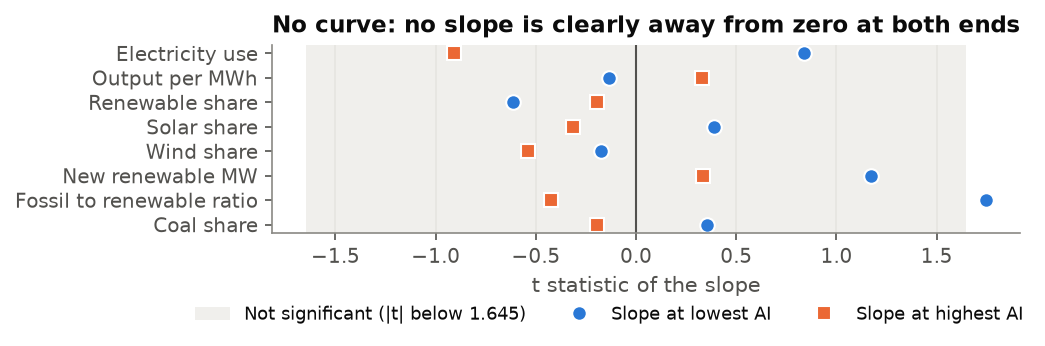

**In plain English.** None of the eight outcomes shows a curve. The slopes at both ends are within the "could be zero" band for every outcome, so there's no turning point to report.

**What we can rule out.** Large curvature: for electricity use, $\beta_2$'s interval is −0.0096 to 0.0036.

In [19]:
outs8 = ["ln_ec", "ln_ee", "renew_share", "solar_share", "wind_share", "new_renew_mw", "fossil_to_renew", "coal_share"]
nice = {"ln_ec": "Electricity use", "ln_ee": "Output per MWh", "renew_share": "Renewable share", "solar_share": "Solar share",
        "wind_share": "Wind share", "new_renew_mw": "New renewable MW", "fossil_to_renew": "Fossil to renewable ratio", "coal_share": "Coal share"}
T(["Outcome", "Curvature $\\beta_2$", "p-value", "t at lowest AI", "t at highest AI", "Passes?"],
  [[nice[y], v(LMP, "b2", outcome=y, controls="ctrl4"), p(LMP, "b2_pval", outcome=y, controls="ctrl4"),
    v(LMP, "t_slope_min", sig=2, outcome=y, controls="ctrl4"), v(LMP, "t_slope_max", sig=2, outcome=y, controls="ctrl4"),
    "Yes" if str(L.row(LMP, outcome=y, controls="ctrl4")["lm_pass"]).upper() == "TRUE" else "No"] for y in outs8],
  "AI squared, H1 design. Read from the corrected file results/2026-11-09/h1/lm_proper.csv.")
fig, ax = plt.subplots(figsize=(7.0, 2.64))
yy = np.arange(len(outs8))[::-1]
ax.axvspan(-1.645, 1.645, color=GRID, alpha=0.6, lw=0, label="Not significant (|t| below 1.645)")
ax.axvline(0, color=INK2, lw=1)
ax.plot([raw(LMP, "t_slope_min", outcome=y, controls="ctrl4") for y in outs8], yy, "o", color=BLUE, ms=7, mec="white", label="Slope at lowest AI")
ax.plot([raw(LMP, "t_slope_max", outcome=y, controls="ctrl4") for y in outs8], yy, "s", color=ORANGE, ms=7, mec="white", label="Slope at highest AI")
ax.set_yticks(yy); ax.set_yticklabels([nice[y] for y in outs8]); ax.grid(axis="y", visible=False)
ax.set_xlabel("t statistic of the slope"); ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.3), ncol=3, fontsize=8.5)
ax.set_title("No curve: no slope is clearly away from zero at both ends")
L.fig(fig, "t statistics of the slope at the lowest and highest AI levels. A curve needs both points outside the gray band, on opposite sides.")
md(f"""**In plain English.** None of the eight outcomes shows a curve. The slopes at both ends are within the "could be zero" band for every outcome, so there's no turning point to report.

**What we can rule out.** Large curvature: for electricity use, $\\beta_2$'s interval is {ci(NLF, sig=2, tag='nonlin_twfe_ai518210sq_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025', coef='ai_sq_lag1')}.""")

In [20]:
L.section(5, "The Fang test")
md(f"""Fang, Lee and Li (2025) report that U.S. states with more AI job postings used more renewable energy from 2018 to 2021. We ask three things: can we reproduce their number, why does it differ on today's data, and does it survive our design? Their AI measure is postings from the Stanford AI Index; their outcome is renewable energy use from EIA SEDS.""")
md("## 5.1 Replication on each EIA data version")
md("""**The question.** Do we get Fang's coefficient with Fang's own model?""")
md(r"""$$\ln RE_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$""")
T(["Symbol", "Plain meaning"], [
 ["$\\ln RE_{st}$", "Renewable energy use from EIA SEDS, in logs"],
 ["$\\ln AI_{st}$", "This year's AI job postings, in logs (no lag)"],
 ["$\\ln EPU_{st}$", "State EPU, in logs"],
 ["$X_{st}$", "Fang's controls: energy price, GDP, population, education"],
 ["$\\alpha_s$", "State fixed effects. **No year fixed effects**, unlike our design"],
], "Symbols in Fang's model (their Table 2, column 6).")
md("""**Analogy.** Re-running a recipe from a cookbook with the same ingredients to check you get the same cake, then trying again with today's flour, which the mill now measures differently.

**What "yes" and "no" would look like.** A successful replication lands inside Fang's confidence interval; a failed one doesn't.""")

# 5. The Fang test

Fang, Lee and Li (2025) report that U.S. states with more AI (artificial intelligence) job postings used more renewable energy from 2018 to 2021. We ask three things: can we reproduce their number, why does it differ on today's data, and does it survive our design? Their AI measure is postings from the Stanford AI Index; their outcome is renewable energy use from EIA (U.S. Energy Information Administration) SEDS (State Energy Data System).

## 5.1 Replication on each EIA data version

**The question.** Do we get Fang's coefficient with Fang's own model?

$$\ln RE_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$

Symbol,Plain meaning
$\ln RE_{st}$,"Renewable energy use from EIA (U.S. Energy Information Administration) SEDS (State Energy Data System), in logs"
$\ln AI_{st}$,"This year's AI (artificial intelligence) job postings, in logs (no lag)"
$\ln EPU_{st}$,"State EPU (Economic Policy Uncertainty index), in logs"
$X_{st}$,"Fang's controls: energy price, GDP (gross domestic product), population, education"
$\alpha_s$,"State fixed effects. No year fixed effects, unlike our design"


**Analogy.** Re-running a recipe from a cookbook with the same ingredients to check you get the same cake, then trying again with today's flour, which the mill now measures differently.

**What "yes" and "no" would look like.** A successful replication lands inside Fang's confidence interval; a failed one doesn't.

EIA (U.S. Energy Information Administration) data version,AI (artificial intelligence) coefficient,95% interval,p-value
Fang's published value,0.0531,,
Today's EIA SEDS,−0.0188,−0.056 to 0.018,p = 0.317
SEDS as published in June 2023 (before the change),0.0348,−0.0011 to 0.071,p = 0.057
Our year-by-year rebuild of the old method,0.0137,−0.026 to 0.054,p = 0.500
"Old method, rough scaling (k = 2.6, check only)",0.0216,−0.018 to 0.062,p = 0.287


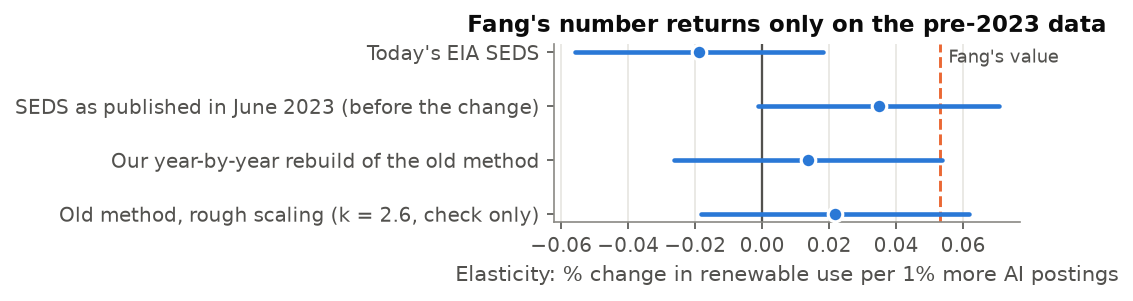

**In plain English.** On today's data, the coefficient is negative and not significant. On the data EIA published in June 2023, before its accounting change, we get about two-thirds of Fang's number (0.0348, p = 0.057), and columns 1 and 2 come close to Fang's (0.0346 and 0.0435 against 0.0428 and 0.0452). Of the gap between today's and the June 2023 data in column 6, 61% comes from the accounting change and the rest from EIA's later data revisions.

**What we can rule out.** On today's data, an elasticity above 0.018: a 10% rise in postings isn't associated with more than about 0.18% more renewable use.

In [21]:
bases = [("Today's EIA SEDS", "current"), ("SEDS as published in June 2023 (before the change)", "archived"),
         ("Our year-by-year rebuild of the old method", "rebuilt"), ("Old method, rough scaling (k = 2.6, check only)", "k26")]
rows = [["Fang's published value", v(T2, "fang_published", ai_measure="ln AI postings", term="AI", column=6), "", ""]]
rows += [[lab, est(F8, tag=t2(b)), ci(F8, sig=2, tag=t2(b)), p(F8, tag=t2(b))] for lab, b in bases]
T(["EIA data version", "AI coefficient", "95% interval", "p-value"], rows,
  f"Fang's Table 2, column 6, on each SEDS version, 2018-2021 with DC, {n(F8, 'N', tag=t2('current'))} state-years.")
fig, ax = plt.subplots(figsize=(7.0, 2.11))
coefplot(ax, [b[0] for b in bases], [raw(F8, "estimate", tag=t2(b)) for _, b in bases], [raw(F8, "ci_lo", tag=t2(b)) for _, b in bases],
         [raw(F8, "ci_hi", tag=t2(b)) for _, b in bases], ref=raw(T2, "fang_published", ai_measure="ln AI postings", term="AI", column=6),
         ref_label="Fang's value", unit="Elasticity: % change in renewable use per 1% more AI postings")
ax.set_title("Fang's number returns only on the pre-2023 data")
L.fig(fig, "Fang's column 6 coefficient on each EIA data version, with 95% intervals; the dashed line is Fang's published value.")
md(f"""**In plain English.** On today's data, the coefficient is negative and not significant. On the data EIA published in June 2023, before its accounting change, we get about two-thirds of Fang's number ({est(F8, tag=t2('archived'))}, {p(F8, tag=t2('archived'))}), and columns 1 and 2 come close to Fang's ({est(F8, tag=t2('archived', 1))} and {est(F8, tag=t2('archived', 2))} against {v(T2, 'fang_published', ai_measure='ln AI postings', term='AI', column=1)} and {v(T2, 'fang_published', ai_measure='ln AI postings', term='AI', column=2)}). Of the gap between today's and the June 2023 data in column 6, {v(GAP, 'share_accounting_rebuild', scale=100, sig=2, ai_measure='ln AI postings', column=6)}% comes from the accounting change and the rest from EIA's later data revisions.

**What we can rule out.** On today's data, an elasticity above {v(F8, 'ci_hi', sig=2, tag=t2('current'))}: a 10% rise in postings isn't associated with more than about {v(F8, 'ci_hi', sig=2, scale=10, tag=t2('current'))}% more renewable use.""")

In [22]:
md("## 5.2 Table A1 check: our data match Fang's")
md("""**The question.** Before blaming the model, are we using the same data? Fang's supplement (Table A1) lists the mean, spread, minimum and maximum of each variable, so we compare ours line by line. The model is a plain comparison, so instead of an equation the check is: difference in means, measured in standard deviations, with differences above 0.25 SD flagged.""")
a1rows = [("ln AI postings", "ext_a1_lnAIp_"), ("ln energy price", "ext_a1_lnEP_"), ("ln population", "ext_a1_lnPOP_"), ("ln education", "ext_a1_lnEDU_"),
          ("ln GDP", "ext_a1_lnGDP_"), ("ln EPU", "ext_a1_lnEPU_"), ("ln renewables, today's SEDS", "ext_a1_lnET_currentSEDS"), ("ln renewables, June 2023 SEDS", "ext_a1_lnET_arch_June2023SEDS")]
T(["Variable", "Our mean", "Fang's mean", "Difference in our SDs", "Reading"],
  [[lab, v(A1, "mean", sig=4, tag=tg), v(A1, "fang_mean", sig=4, tag=tg), v(A1, "diff_in_our_sd", sig=2, tag=tg),
    {"ext_a1_lnGDP_": "GDP base year: 2017 vs 2012 dollars", "ext_a1_lnEPU_": "Fang's index is about double ours; drops out in logs with state effects",
     "ext_a1_lnET_currentSEDS": "Today's data sit below Fang's", "ext_a1_lnET_arch_June2023SEDS": "Matches: Fang used the old data"}.get(tg, "Matches")]
   for lab, tg in a1rows],
  f"Our 2018-2021 data against Fang's Table A1, {n(A1, 'N', tag='ext_a1_lnAIp_')} state-years each.",
  "Pending: a rerun of Fang's model with GDP in chained 2012 dollars (BEA's earlier base year) hasn't been done. The 0.09 log-point GDP gap is the size a base-year change would give, and a constant shift drops out with state fixed effects, but chain revisions vary by state and year, so the rerun is still owed.")
md(f"""**In plain English.** Our AI series is the same as Fang's: the means differ by {v(A1, 'diff_in_our_sd', sig=1, tag='ext_a1_lnAIp_')} SD, and the minimum and maximum match too. Renewable use matches only on the June 2023 data, which is how we know Fang used the old accounting. **Pending:** the GDP rerun in 2012 dollars, flagged in the table note.""")

## 5.2 Table A1 check: our data match Fang's

**The question.** Before blaming the model, are we using the same data? Fang's supplement (Table A1) lists the mean, spread, minimum and maximum of each variable, so we compare ours line by line. The model is a plain comparison, so instead of an equation the check is: difference in means, measured in standard deviations, with differences above 0.25 SD (standard deviation) flagged.

Variable,Our mean,Fang's mean,Difference in our SDs,Reading
ln AI (artificial intelligence) postings,7.701,7.700,0.00056,Matches
ln energy price,2.927,2.930,−0.013,Matches
ln population,8.272,8.270,0.0024,Matches
ln education,4.232,4.230,0.0055,Matches
ln GDP (gross domestic product),12.35,12.26,0.086,GDP base year: 2017 vs 2012 dollars
ln EPU (Economic Policy Uncertainty index),5.382,6.090,−1.2,Fang's index is about double ours; drops out in logs with state effects
"ln renewables, today's SEDS (State Energy Data System)",11.44,11.79,−0.32,Today's data sit below Fang's
"ln renewables, June 2023 SEDS",11.83,11.79,0.038,Matches: Fang used the old data


**In plain English.** Our AI series is the same as Fang's: the means differ by 0.0006 SD, and the minimum and maximum match too. Renewable use matches only on the June 2023 data, which is how we know Fang used the old accounting. **Pending:** the GDP (gross domestic product) rerun in 2012 dollars, flagged in the table note.

## 5.3 The bridge from Fang's design to ours

**The question.** Which design difference makes Fang's result change? We move from Fang's model to ours one step at a time.

Each step adds one change to Fang's equation: (1) year fixed effects $\delta_t$; (2) the sample that has a lagged value; (3) last year's AI instead of this year's; (4) standard errors clustered by state; (5) a longer sample; (6) dropping DC (District of Columbia). The final step is our H1 design with Fang's outcome:
$$\ln RE_{st} = \beta \ln AI_{s,t-1} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$

**Analogy.** Changing one ingredient at a time to find out which one made the cake fall.

**What "yes" and "no" would look like.** If Fang's association were robust, the coefficient would stay positive at every step.

Step,AI postings,p-value,Data-center jobs,p-value
"Fang's model, today's data",−0.0188,p = 0.317,−0.0655,p = 0.229
+ year effects,−0.109,p = 0.004,−0.0628,p = 0.262
+ lag sample,−0.105,p = 0.039,−0.0242,p = 0.749
+ last year's AI,−0.0761,p = 0.112,−0.112,p = 0.110
+ clustered errors,−0.0761,p = 0.148,−0.112,p = 0.193
+ longer sample,−0.0496,p = 0.094,−0.0279,p = 0.578
+ drop DC (District of Columbia) (our design),−0.0479,p = 0.109,−0.0567,p = 0.208


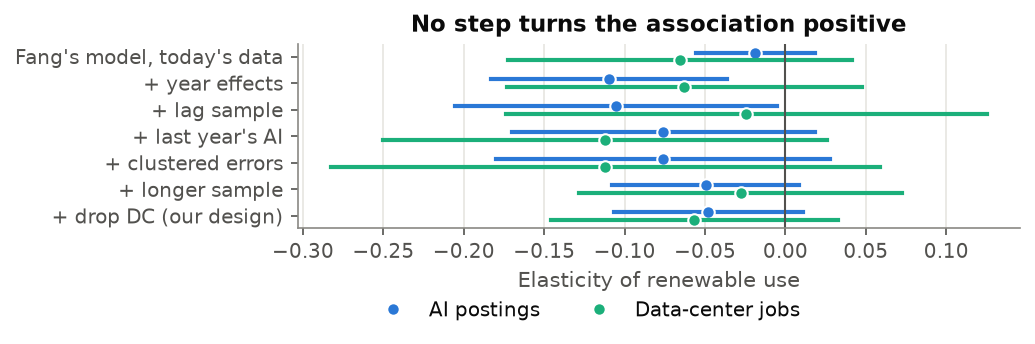

**In plain English.** On today's data, Fang's model already gives a small negative number, and adding year effects makes it clearly negative (p = 0.004). By our final design neither measure is significant: postings −0.0479 (p = 0.109) and data-center jobs −0.0567 (p = 0.208). Data-center jobs are the more reliable measure for longer samples, because almost every postings year comes from a different AI Index edition.

**What we can rule out.** In our design, per typical within-state swing in log postings, renewable use moves between −2.6 to 0.27%; for data-center jobs, −3.2 to 0.70%.

In [23]:
md("## 5.3 The bridge from Fang's design to ours")
md("""**The question.** Which design difference makes Fang's result change? We move from Fang's model to ours one step at a time.""")
md(r"""Each step adds one change to Fang's equation: (1) year fixed effects $\delta_t$; (2) the sample that has a lagged value; (3) last year's AI instead of this year's; (4) standard errors clustered by state; (5) a longer sample; (6) dropping DC. The final step is our H1 design with Fang's outcome:
$$\ln RE_{st} = \beta \ln AI_{s,t-1} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \delta_t + \varepsilon_{st}$$""")
md("""**Analogy.** Changing one ingredient at a time to find out which one made the cake fall.

**What "yes" and "no" would look like.** If Fang's association were robust, the coefficient would stay positive at every step.""")
steps = [("s0-fang", "Fang's model, today's data"), ("s1-yearfe", "+ year effects"), ("s2-sample", "+ lag sample"), ("s3-lag", "+ last year's AI"),
         ("s4-cluster", "+ clustered errors"), ("s5-extend", "+ longer sample"), ("s6-noDC", "+ drop DC (our design)")]
def btg(st, m):
    rr = tbl(FR).query("block=='bridge' and term=='AI' and outcome=='lnET' and spec==@st and ai_measure==@m")
    return rr.tag.iloc[0]
T(["Step", "AI postings", "p-value", "Data-center jobs", "p-value"],
  [[lab, est(FR, tag=btg(st, "aipostings")), p(FR, tag=btg(st, "aipostings")), est(FR, tag=btg(st, "dcjobs")), p(FR, tag=btg(st, "dcjobs"))] for st, lab in steps],
  "Bridge from Fang's model to ours on today's EIA SEDS: AI coefficient (elasticity) at each step.")
fig, ax = plt.subplots(figsize=(7.0, 2.64))
yy = np.arange(len(steps))[::-1]
for k, (m, c, off, lab) in enumerate([("aipostings", BLUE, 0.15, "AI postings"), ("dcjobs", AQUA, -0.15, "Data-center jobs")]):
    for i, (st, _) in enumerate(steps):
        t = btg(st, m)
        ax.plot([raw(FR, "ci_lo", tag=t), raw(FR, "ci_hi", tag=t)], [yy[i] + off] * 2, color=c, lw=2)
        ax.plot([raw(FR, "estimate", tag=t)], [yy[i] + off], "o", color=c, ms=6, mec="white", label=lab if i == 0 else None)
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(yy); ax.set_yticklabels([s_[1] for s_ in steps]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Elasticity of renewable use"); ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.3), ncol=2); ax.set_title("No step turns the association positive")
L.fig(fig, "AI coefficient at each step of the bridge, with 95% intervals, for both AI measures.")
md(f"""**In plain English.** On today's data, Fang's model already gives a small negative number, and adding year effects makes it clearly negative ({p(FR, tag=btg('s1-yearfe', 'aipostings'))}). By our final design neither measure is significant: postings {est(FR, tag=BR_P)} ({p(FR, tag=BR_P)}) and data-center jobs {est(FR, tag=BR_J)} ({p(FR, tag=BR_J)}). Data-center jobs are the more reliable measure for longer samples, because almost every postings year comes from a different AI Index edition.

**What we can rule out.** In our design, per typical within-state swing in log postings, renewable use moves between {ci(RO, lo='ci_lo_per_sd', hi='ci_hi_per_sd', tag=BR_P)}%; for data-center jobs, {ci(RO, lo='ci_lo_per_sd', hi='ci_hi_per_sd', tag=BR_J)}%.""")

## 5.4 The trend test and placebo industries

**The question.** Is Fang's association specific to AI, or would any growing series show it?

$$\ln RE_{st} = \beta \ln AI_{st} + \tau\, t + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$
Placebo: replace $\ln AI_{st}$ with $\ln \text{Jobs}^{\text{pet care}}_{st}$ (or distillery jobs).

Symbol,Plain meaning
"$\tau\, t$",A straight-line national trend in years
$\ln \text{Jobs}^{\text{pet care}}$,"Log jobs in pet care (except veterinary), from BLS (Bureau of Labor Statistics) QCEW (Quarterly Census of Employment and Wages). Distilleries are a second placebo"


**Analogy.** If your "AI detector" also beeps for pet groomers and whiskey makers, it's detecting growth, not AI.

**What "yes" and "no" would look like.** If Fang's result were about AI: the AI coefficient survives a trend, and the placebo industries show nothing.

Version (June 2023 SEDS),Coefficient,95% interval,p-value,State-years
"Fang's model, AI (artificial intelligence) postings",0.0348,−0.0011 to 0.071,p = 0.057,204
"+ linear trend, AI postings",−0.0419,−0.095 to 0.011,p = 0.121,204
Pet-care jobs instead of AI,0.298,0.10 to 0.50,p = 0.003,202
Distillery jobs instead of AI,0.100,0.0048 to 0.20,p = 0.040,135


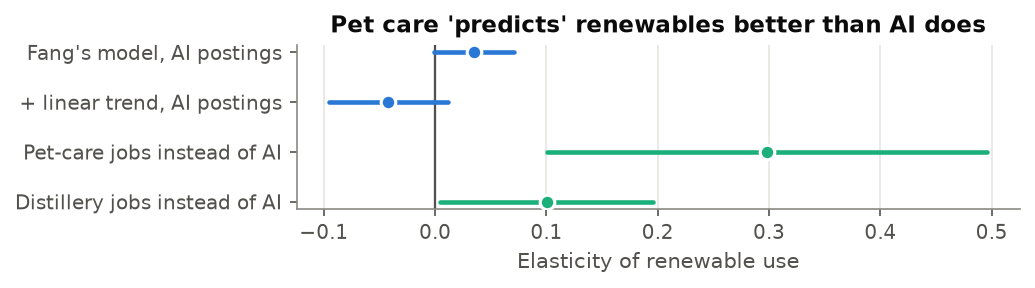

**In plain English.** A simple trend turns Fang's positive coefficient negative (−0.0419, p = 0.121), and pet-care jobs are associated with renewables more strongly than AI postings (0.298, p = 0.003). Fang's model picks up anything that grew over 2018-2021.

**What we can rule out.** That the association is specific to AI in Fang's design.

In [24]:
md("## 5.4 The trend test and placebo industries")
md("""**The question.** Is Fang's association specific to AI, or would any growing series show it?""")
md(r"""$$\ln RE_{st} = \beta \ln AI_{st} + \tau\, t + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$
Placebo: replace $\ln AI_{st}$ with $\ln \text{Jobs}^{\text{pet care}}_{st}$ (or distillery jobs).""")
T(["Symbol", "Plain meaning"], [
 ["$\\tau\\, t$", "A straight-line national trend in years"],
 ["$\\ln \\text{Jobs}^{\\text{pet care}}$", "Log jobs in pet care (except veterinary), from BLS QCEW. Distilleries are a second placebo"],
], "Symbols in the trend and placebo tests; the rest is Fang's model.")
md("""**Analogy.** If your "AI detector" also beeps for pet groomers and whiskey makers, it's detecting growth, not AI.

**What "yes" and "no" would look like.** If Fang's result were about AI: the AI coefficient survives a trend, and the placebo industries show nothing.""")
TT = [("Fang's model, AI postings", "ext_p2_p1trend_fang6_aipostings_lnET_arch_51s2018_2021_AI"),
      ("+ linear trend, AI postings", "ext_p2_p1trend_fang6trend_aipostings_lnET_arch_51s2018_2021_AI"),
      ("Pet-care jobs instead of AI", "ext_p2_p1placebo_fang6_petcare_lnET_arch_51s2018_2021_AI"),
      ("Distillery jobs instead of AI", "ext_p2_p1placebo_fang6_distilleries_lnET_arch_43s2018_2021_AI")]
T(["Version (June 2023 SEDS)", "Coefficient", "95% interval", "p-value", "State-years"],
  [[lab, est(P2, tag=tg), ci(P2, sig=2, tag=tg), p(P2, tag=tg), n(P2, "N", tag=tg)] for lab, tg in TT],
  "Fang's column 6 on the June 2023 SEDS data that reproduce Fang: trend test and placebo industries.")
fig, ax = plt.subplots(figsize=(7.0, 2.02))
coefplot(ax, [r[0] for r in TT], [raw(P2, "estimate", tag=t) for _, t in TT], [raw(P2, "ci_lo", tag=t) for _, t in TT],
         [raw(P2, "ci_hi", tag=t) for _, t in TT], colors=[BLUE, BLUE, AQUA, AQUA], unit="Elasticity of renewable use")
ax.set_title("Pet care 'predicts' renewables better than AI does")
L.fig(fig, "Trend test and placebo industries in Fang's model on June 2023 SEDS, with 95% intervals. Green rows are placebo industries.")
md(f"""**In plain English.** A simple trend turns Fang's positive coefficient negative ({est(P2, tag=TT[1][1])}, {p(P2, tag=TT[1][1])}), and pet-care jobs are associated with renewables more strongly than AI postings ({est(P2, tag=TT[2][1])}, {p(P2, tag=TT[2][1])}). Fang's model picks up anything that grew over 2018-2021.

**What we can rule out.** That the association is specific to AI in Fang's design.""")

## 5.5 EPU (Economic Policy Uncertainty index) moderation

**The question.** Is the AI association stronger where policy uncertainty is higher, as Fang report?

$$\ln RE_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \phi\,(\ln AI_{st} \times \ln EPU_{st}) + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$

Symbol,Plain meaning
$\phi$,How the AI (artificial intelligence) association changes as EPU rises (the moderation)


**Analogy.** Does an umbrella sell better on rainy days? The interaction asks whether AI "sells" renewables better when policy is uncertain.

**What "yes" and "no" would look like.** "Yes": $\phi$ clearly nonzero in both designs. "No": significant only without year effects.

Design,Interaction $\phi$,95% interval,p-value
Fang's design,0.0193,0.0071 to 0.032,p = 0.002
Our design,0.0117,−0.0049 to 0.028,p = 0.163


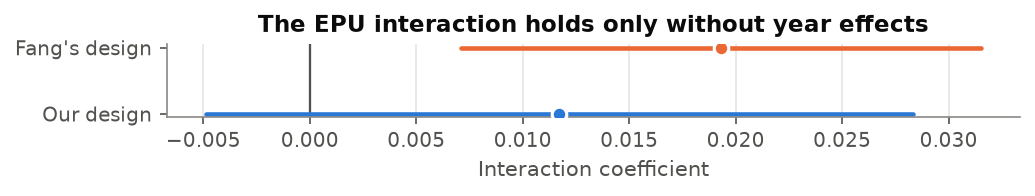

**In plain English.** In Fang's design the interaction is positive (p = 0.002); in ours it isn't significant (p = 0.163). Like the main result, it depends on leaving out nationwide year effects.

**What we can rule out.** In our design, an interaction above 0.028.

In [25]:
md("## 5.5 EPU moderation")
md("""**The question.** Is the AI association stronger where policy uncertainty is higher, as Fang report?""")
md(r"""$$\ln RE_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \phi\,(\ln AI_{st} \times \ln EPU_{st}) + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$""")
T(["Symbol", "Plain meaning"], [["$\\phi$", "How the AI association changes as EPU rises (the moderation)"]], "Symbol added for EPU moderation; the rest is Fang's model (our version adds year effects and a lag).")
md("""**Analogy.** Does an umbrella sell better on rainy days? The interaction asks whether AI "sells" renewables better when policy is uncertain.

**What "yes" and "no" would look like.** "Yes": $\\phi$ clearly nonzero in both designs. "No": significant only without year effects.""")
E1 = "fang_mod_fang-lnEPUS_aipostings_contemp_state_iid_lnET_51s2018_2021_AI_x_EPU"; E2 = "fang_mod_twfe-lnEPUS_aipostings_lag1_state-year_cl_lnET_50s2019_2024_AI_x_EPU"
T(["Design", "Interaction $\\phi$", "95% interval", "p-value"],
  [["Fang's design", est(FR, tag=E1), ci(FR, sig=2, tag=E1), p(FR, tag=E1)], ["Our design", est(FR, tag=E2), ci(FR, sig=2, tag=E2), p(FR, tag=E2)]],
  "AI postings x state EPU, today's SEDS.")
fig, ax = plt.subplots(figsize=(7.0, 1.41))
coefplot(ax, ["Fang's design", "Our design"], [raw(FR, "estimate", tag=t) for t in (E1, E2)], [raw(FR, "ci_lo", tag=t) for t in (E1, E2)],
         [raw(FR, "ci_hi", tag=t) for t in (E1, E2)], colors=[ORANGE, BLUE], unit="Interaction coefficient")
ax.set_title("The EPU interaction holds only without year effects")
L.fig(fig, "AI x EPU interaction in each design, with 95% intervals.")
md(f"""**In plain English.** In Fang's design the interaction is positive ({p(FR, tag=E1)}); in ours it isn't significant ({p(FR, tag=E2)}). Like the main result, it depends on leaving out nationwide year effects.

**What we can rule out.** In our design, an interaction above {v(FR, 'ci_hi', sig=2, tag=E2)}.""")

In [26]:
md("## 5.6 Results by renewable type, subgroups and Supplement B")
md(r"""**The question.** Do Fang's findings by type of renewable, by group of states, and for fossil fuels hold up? Each uses Fang's equation with a different outcome (wind, solar, hydro, geothermal, biomass; fossil fuels) or on a subset of states (high vs low price; net producers vs consumers):
$$\ln RE^{\text{type}}_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$""")
md("""**Analogy.** If a medicine works, it should work in each age group, not only in the pooled study. **"Yes"** would be consistent results across types and groups; **"no"** is results that come and go with the specification.""")
ty = [("Wind", "lnWind"), ("Solar", "lnSolar"), ("Hydro", "lnHydro"), ("Geothermal", "lnGeo"), ("Biomass", "lnBio")]
def tyt(sp, y):
    return tbl(FR).query("block=='type' and ai_measure=='aipostings' and spec==@sp and outcome==@y").tag.iloc[0]
T(["Renewable type", "Fang's design", "p-value", "Our design", "p-value"],
  [[lab, est(FR, tag=tyt("fang", y)), p(FR, tag=tyt("fang", y)), est(FR, tag=tyt("twfe", y)), p(FR, tag=tyt("twfe", y))] for lab, y in ty],
  "AI postings and each renewable type, today's SEDS (elasticities).")
md(f"""By type, solar is strongly positive in Fang's design ({p(FR, tag=tyt('fang', 'lnSolar'))}) and not in ours ({p(FR, tag=tyt('twfe', 'lnSolar'))}): solar grew everywhere over these years, and year effects absorb that.

**Subgroups.** Fang split states by electricity price and by whether they produce more electricity than they use. Fang's headline price and net-producer splits don't reproduce on today's data. Who counts as a "net producer" depends on the definition: our rule gives {n(NPC, 'net_producer_state_years', tag='fang_netdef_gen_gt_sales_difference_aipostings_producer_minus_consumer')} producer state-years against Fang's count in their Table 3, and the producer-minus-consumer gap is significant only on our rule. We treat the splits as exploratory.

**Supplement B (fossil fuels).** Fang check that AI goes with *less* fossil fuel. On the same samples, Fang's coal coefficient ({v(B1, 'fang_ai', tag='ext_b1_fang6_aipostings_ln_coal_current')}) falls inside our interval (ours {est(B1, tag='ext_b1_fang6_aipostings_ln_coal_current')}), and so does gas; petroleum doesn't (Fang {v(B1, 'fang_ai', tag='ext_b1_fang6_aipostings_ln_petroleum_current')}, ours {est(B1, tag='ext_b1_fang6_aipostings_ln_petroleum_current')}). None is significant in either study.""")
md("""**Verdict: why Fang found a positive association and we don't.** Three things, in order of size. **First, the data version:** EIA's 2023 change in how SEDS counts wind, solar, hydro and geothermal shrank renewable energy in a way that differs by state; on the old data we get most of Fang's number back. **Second, year effects:** renewables and AI postings both rose nationally in 2018-2021, so without year effects any growing series, including pet-care jobs, looks associated with renewables. **Third, timing and sample:** with last year's AI, clustered errors and a longer sample, neither AI measure is significant. Fang's data are fine (Table A1 matches); the design is what differs.""")

## 5.6 Results by renewable type, subgroups and Supplement B

**The question.** Do Fang's findings by type of renewable, by group of states, and for fossil fuels hold up? Each uses Fang's equation with a different outcome (wind, solar, hydro, geothermal, biomass; fossil fuels) or on a subset of states (high vs low price; net producers vs consumers):
$$\ln RE^{\text{type}}_{st} = \beta \ln AI_{st} + \lambda \ln EPU_{st} + \gamma' X_{st} + \alpha_s + \varepsilon_{st}$$

**Analogy.** If a medicine works, it should work in each age group, not only in the pooled study. **"Yes"** would be consistent results across types and groups; **"no"** is results that come and go with the specification.

Renewable type,Fang's design,p-value,Our design,p-value
Wind,0.0836,p = 0.078,−0.0107,p = 0.860
Solar,0.383,p < 0.001,0.119,p = 0.411
Hydro,0.0212,p = 0.615,0.0142,p = 0.821
Geothermal,0.0414,p = 0.543,0.197,p = 0.285
Biomass,−0.113,p < 0.001,−0.0785,p = 0.016


By type, solar is strongly positive in Fang's design (p < 0.001) and not in ours (p = 0.411): solar grew everywhere over these years, and year effects absorb that.

**Subgroups.** Fang split states by electricity price and by whether they produce more electricity than they use. Fang's headline price and net-producer splits don't reproduce on today's data. Who counts as a "net producer" depends on the definition: our rule gives 120 producer state-years against Fang's count in their Table 3, and the producer-minus-consumer gap is significant only on our rule. We treat the splits as exploratory.

**Supplement B (fossil fuels).** Fang check that AI goes with *less* fossil fuel. On the same samples, Fang's coal coefficient (−0.178) falls inside our interval (ours −0.119), and so does gas; petroleum doesn't (Fang −0.0160, ours 0.00672). None is significant in either study.

**Verdict: why Fang found a positive association and we don't.** Three things, in order of size. **First, the data version:** EIA's 2023 change in how SEDS counts wind, solar, hydro and geothermal shrank renewable energy in a way that differs by state; on the old data we get most of Fang's number back. **Second, year effects:** renewables and AI postings both rose nationally in 2018-2021, so without year effects any growing series, including pet-care jobs, looks associated with renewables. **Third, timing and sample:** with last year's AI, clustered errors and a longer sample, neither AI measure is significant. Fang's data are fine (Table A1 matches); the design is what differs.

In [27]:
L.section(6, "Extensions")
md(r"""All extensions use the H1 design with a different outcome or AI measure, so the equation is H1's: $y_{st} = \beta AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$. A result counts as a finding only if its Benjamini-Hochberg q-value is below 0.10 within its family of tests and next year's AI doesn't explain it as well. **Analogy:** running many tests is like buying many lottery tickets, and the q-value adjusts for how many tickets we bought. **"Yes"** would be a q-value below 0.10 with a clean timing test; **"no"** is everything else.""")
md("## 6.1 AI by renewable type")
W1 = "ext_bytype_twfe_aipostp1000_lag1_ctrl4_w9901_cl-state_ln_gen_wind_50s"
SS = "ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_share_solar_50s"
GS = "ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_gen_solar_50s"
bt_rows = [("Wind generation (log), AI postings", W1), ("Wind generation (log), data-center jobs", "ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_gen_wind_50s"),
           ("Solar share, data-center jobs", SS), ("Solar generation (log), data-center jobs", GS),
           ("Solar additions per 1,000 MW, data-center jobs", "ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_add_solar_per1000_50s")]
T(["Outcome and AI measure", "Coefficient", "p-value", "q-value"], [[lab, est(BT, tag=tg), p(BT, tag=tg), v(BT, "qval", dec=3, tag=tg)] for lab, tg in bt_rows],
  "Selected by-type rows; the full family is in results/2026-11-07/extend/s2_bytype_results.csv.")
md(f"""**In plain English.** Only {n(EXS, 'value', tag='ext_bytype_rows_q10')} by-type row passes the multiple-testing bar: AI postings and wind generation ({est(BT, tag=W1)}, q = {v(BT, 'qval', dec=3, tag=W1)}). It runs against the expected sign and loses significance with state trends, so it's exploratory. Solar shows nothing.""")
md("## 6.2 What AI is associated with")
imp = [("Commercial electricity sales per person (log)", "ln_sales_com_pc"), ("Industrial sales per person (log)", "ln_sales_ind_pc"), ("Residential sales per person (log)", "ln_sales_res_pc"),
       ("Commercial price (cents per kWh)", "price_com861_c_kwh"), ("Gas share of generation", "share_gas"), ("Wind added per 1,000 MW", "add_wind_per1000"),
       ("Gas added per 1,000 MW", "add_gas_per1000"), ("Net electricity imports (share of sales)", "net_imports"), ("Power-sector CO2 (log)", "ln_co2_power")]
def itg(y):
    return tbl(IMP).query("ai_measure=='ai518210' and outcome==@y").tag.iloc[0]
T(["Outcome (data-center jobs)", "Coefficient", "p-value", "q-value"], [[lab, est(IMP, tag=itg(y)), p(IMP, tag=itg(y)), v(IMP, "qval", dec=3, tag=itg(y))] for lab, y in imp],
  "What data-center jobs are associated with: selected outcomes from the 30-row family.")
md(f"""**In plain English.** None of the 30 rows (15 outcomes, two AI measures) passes the bar; the smallest q-value is {v(EXS, 'value', dec=3, tag='ext_impact_min_q')}. Per typical within-state swing in data-center jobs, commercial electricity sales per person move between {ci(BND, scale=100, lo='per_sd_lo', hi='per_sd_hi', tag='ext_impact_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_sales_com_pc_50s')}%.""")

# 6. Extensions

All extensions use the H1 design with a different outcome or AI (artificial intelligence) measure, so the equation is H1's: $y_{st} = \beta AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$. A result counts as a finding only if its Benjamini-Hochberg q-value is below 0.10 within its family of tests and next year's AI doesn't explain it as well. **Analogy:** running many tests is like buying many lottery tickets, and the q-value adjusts for how many tickets we bought. **"Yes"** would be a q-value below 0.10 with a clean timing test; **"no"** is everything else.

## 6.1 AI by renewable type

Outcome and AI (artificial intelligence) measure,Coefficient,p-value,q-value
"Wind generation (log), AI postings",−0.0477,p = 0.002,0.086
"Wind generation (log), data-center jobs",−0.181,p = 0.016,0.147
"Solar share, data-center jobs",−0.0000593,p = 0.984,0.984
"Solar generation (log), data-center jobs",0.0420,p = 0.746,0.777
"Solar additions per 1,000 MW (megawatts), data-center jobs",−0.599,p = 0.755,0.777


**In plain English.** Only 1 by-type row passes the multiple-testing bar: AI postings and wind generation (−0.0477, q = 0.086). It runs against the expected sign and loses significance with state trends, so it's exploratory. Solar shows nothing.

## 6.2 What AI is associated with

Outcome (data-center jobs),Coefficient,p-value,q-value
Commercial electricity sales per person (log),−0.00372,p = 0.764,0.929
Industrial sales per person (log),−0.00493,p = 0.714,0.929
Residential sales per person (log),0.000576,p = 0.824,0.929
Commercial price (cents per kWh (kilowatt-hour)),0.220,p = 0.342,0.803
Gas share of generation,0.00343,p = 0.588,0.929
"Wind added per 1,000 MW (megawatts)",1.89,p = 0.015,0.436
"Gas added per 1,000 MW",−2.75,p = 0.045,0.673
Net electricity imports (share of sales),0.000773,p = 0.966,0.966
Power-sector CO2 (carbon dioxide) (log),−0.00516,p = 0.836,0.929


**In plain English.** None of the 30 rows (15 outcomes, two AI measures) passes the bar; the smallest q-value is 0.436. Per typical within-state swing in data-center jobs, commercial electricity sales per person move between −1.6 to 1.2%.

## 6.3 What drove the national renewables trend

Year effects absorb everything national. To ask what's inside them, we replace $\delta_t$ with measured national drivers: RPS (Renewable Portfolio Standard) targets, solar and wind costs, the ITC (Investment Tax Credit) and PTC (Production Tax Credit) from CRS (Congressional Research Service) reports and federal law, and natural gas prices:
$$y_{st} = \beta AI_{s,t-1} + \sum_k \kappa_k D_{kt} + \text{controls} + \alpha_s + \varepsilon_{st}$$
where $D_{kt}$ are the drivers and $\kappa_k$ their associations. **Analogy:** opening the "national weather" box to see whether it's sun, wind or rain. **"Yes" for AI** would be a coefficient that changes a lot once the drivers replace the year effects.

Model (renewable share),AI coefficient,p-value
State effects only,−0.0124,p = 0.046
Measured drivers,−0.0111,p = 0.073
State and year effects (H1),−0.0101,p = 0.100


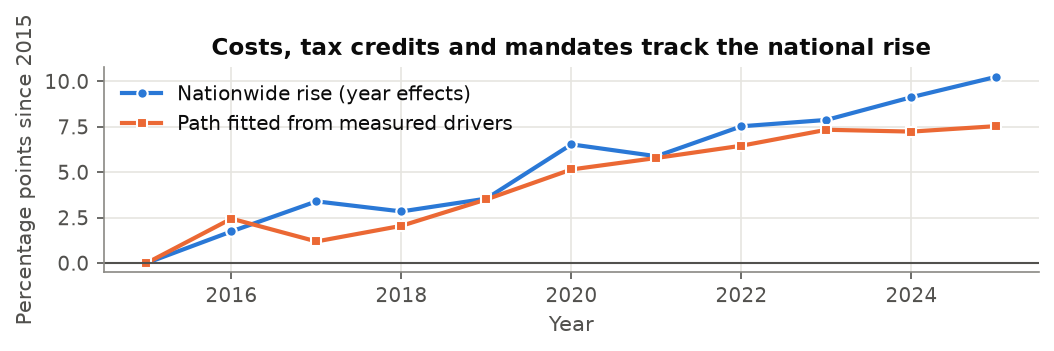

**In plain English.** The AI coefficient is nearly the same whether we use state effects only (−0.0124), measured drivers (−0.0111) or year effects (−0.0101), so the national rise isn't loading on AI. The drivers' fitted path correlates with the year effects at 0.95. That's consistent with costs, tax credits and mandates driving the trend, but not proof: any rising series correlates with a rising trend.

In [28]:
md("## 6.3 What drove the national renewables trend")
md(r"""Year effects absorb everything national. To ask what's inside them, we replace $\delta_t$ with measured national drivers: RPS targets, solar and wind costs, the ITC and PTC from CRS reports and federal law, and natural gas prices:
$$y_{st} = \beta AI_{s,t-1} + \sum_k \kappa_k D_{kt} + \text{controls} + \alpha_s + \varepsilon_{st}$$
where $D_{kt}$ are the drivers and $\kappa_k$ their associations. **Analogy:** opening the "national weather" box to see whether it's sun, wind or rain. **"Yes" for AI** would be a coefficient that changes a lot once the drivers replace the year effects.""")
dm = [("State effects only", "ext_natl_statefe_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s"), ("Measured drivers", "ext_natl_drivers_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s"),
      ("State and year effects (H1)", "ext_natl_twfe_ai518210_lag1_ctrl4_w9901_cl-state_renew_share_50s")]
T(["Model (renewable share)", "AI coefficient", "p-value"], [[lab, est(DRV, tag=tg), p(DRV, tag=tg)] for lab, tg in dm], "The AI coefficient barely moves across ways of handling the national trend.")
pth = tbl(PATH)
fig, ax = plt.subplots(figsize=(7.0, 2.29))
ax.plot(pth.year, 100 * pth.year_effect, "-o", color=BLUE, lw=2, ms=5, mec="white", label="Nationwide rise (year effects)")
ax.plot(pth.year, 100 * pth.driver_path, "-s", color=ORANGE, lw=2, ms=5, mec="white", label="Path fitted from measured drivers")
ax.axhline(0, color=INK2, lw=1); ax.set_xlabel("Year"); ax.set_ylabel("Percentage points since 2015"); ax.legend(loc="upper left")
ax.set_title("Costs, tax credits and mandates track the national rise")
L.fig(fig, "The national rise in the renewable share (year effects, relative to 2015) and the path fitted from measured national drivers.")
md(f"""**In plain English.** The AI coefficient is nearly the same whether we use state effects only ({est(DRV, tag=dm[0][1])}), measured drivers ({est(DRV, tag=dm[1][1])}) or year effects ({est(DRV, tag=dm[2][1])}), so the national rise isn't loading on AI. The drivers' fitted path correlates with the year effects at {v(PF, 'correlation', sig=2, tag='ext_natl_pathfit_ai518210_drivers_renew_share')}. That's consistent with costs, tax credits and mandates driving the trend, but not proof: any rising series correlates with a rising trend.""")

## 6.4 The AI index and the relevance test

**A broader AI measure.** Jobs are one window on AI. We also built an "infrastructure + talent" index from QCEW (Quarterly Census of Employment and Wages) data-center jobs, establishments and wages, AI postings, and OEWS (Occupational Employment and Wage Statistics) research scientists (2018-2023, 43 states). Its parts hang together (Cronbach's alpha 0.73), and it correlates at 0.55 with the BTOS (Business Trends and Outlook Survey) 2024 share of firms using AI. Across its 136 rows per sample, none passes the bar (smallest q-value 0.863).

**The relevance test.** Before asking what AI does to renewables, we check whether our AI measure tracks electricity demand at all: $\ln \text{CommercialSales}_{st} = \beta AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$, pooled and with a separate slope for each state. **Analogy:** before using a thermometer to study fevers, check that it moves when you hold it in warm water. **"Yes"** would be a clearly positive pooled slope.

Version,Slope,Rank among 50 states,Note
"Pooled, all states",−0.0037,,p = 0.764
Virginia,0.24,3,Descriptive: one state
Texas,0.098,7,Descriptive: one state
Georgia,0.020,21,Descriptive: one state


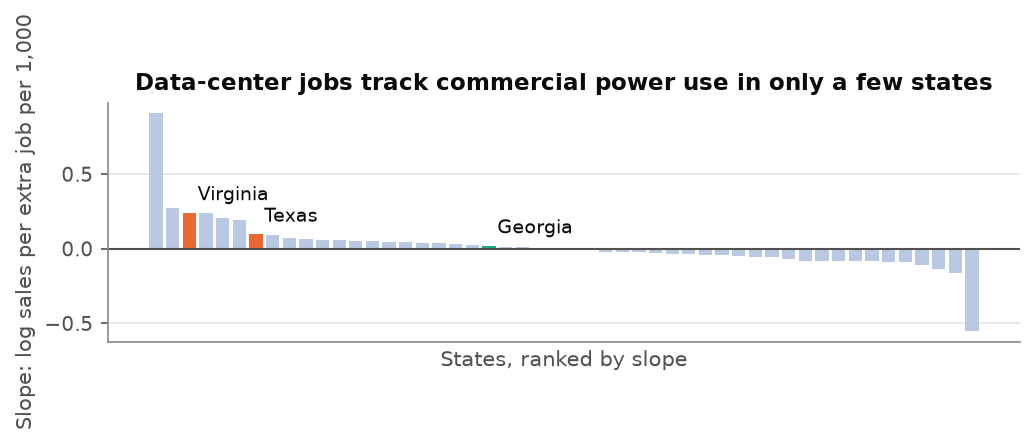

**In plain English.** Pooled across states, data-center jobs don't track commercial electricity use (p = 0.764). They do in Virginia (rank 3 of 50) and Texas (rank 7), the two largest data-center markets. Georgia's own slope is small (rank 21). So for most states our AI measure is a weak window on data-center power demand, which limits what any of our models can see.

**Groupings.** We also grouped states by AI investment, data-center jobs per TWh (terawatt-hours) of sales and land per TWh. No grouping difference survives the multiple-testing correction on all 50 states (smallest q-value 0.158); the land-based grouping that looked significant is driven by Alaska.

In [29]:
md("## 6.4 The AI index and the relevance test")
md(f"""**A broader AI measure.** Jobs are one window on AI. We also built an "infrastructure + talent" index from QCEW data-center jobs, establishments and wages, AI postings, and OEWS research scientists (2018-2023, {n(DIA, 'value', statistic='states (main)')} states). Its parts hang together (Cronbach's alpha {v(DIA, 'value', sig=2, statistic='Cronbach alpha, 5 components')}), and it correlates at {v(XST, 'pearson_index_a_2024', sig=2, check='BTOS 2024 average share of firms using AI')} with the BTOS 2024 share of firms using AI. Across its {n(EXS, 'value', tag='ext_index_rows_per_sample')} rows per sample, none passes the bar (smallest q-value {v(EXS, 'value', dec=3, tag='ext_index_min_q_all50')}).""")
md(r"""**The relevance test.** Before asking what AI does to renewables, we check whether our AI measure tracks electricity demand at all: $\ln \text{CommercialSales}_{st} = \beta AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$, pooled and with a separate slope for each state. **Analogy:** before using a thermometer to study fevers, check that it moves when you hold it in warm water. **"Yes"** would be a clearly positive pooled slope.""")
VAt, TXt, GAt = (f"ext_p2b_permrank_ai518210_all50_{x}" for x in ("VA", "TX", "GA"))
POOL = "ext_p2_relevance_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_sales_com_pc_50s_pooled"
T(["Version", "Slope", "Rank among 50 states", "Note"], [
 ["Pooled, all states", v(REL, "slope", sig=2, tag=POOL), "", p(REL, tag=POOL)],
 ["Virginia", v(RNK, "slope", sig=2, tag=VAt), n(RNK, "rank_desc", tag=VAt), "Descriptive: one state"],
 ["Texas", v(RNK, "slope", sig=2, tag=TXt), n(RNK, "rank_desc", tag=TXt), "Descriptive: one state"],
 ["Georgia", v(RNK, "slope", sig=2, tag=GAt), n(RNK, "rank_desc", tag=GAt), "Descriptive: one state"],
], "Commercial electricity sales per person on data-center jobs: pooled slope and per-state slopes.")
sl = tbl(SLP).sort_values("slope", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.0, 2.29))
cols = [ORANGE if st_ in ("VA", "TX") else (AQUA if st_ == "GA" else "#b9c9e3") for st_ in sl.state]
ax.bar(range(len(sl)), sl.slope, color=cols, width=0.8)
for st_, nm in [("VA", "Virginia"), ("TX", "Texas"), ("GA", "Georgia")]:
    i = int(sl.index[sl.state == st_][0]); ax.annotate(nm, (i, sl.slope[i]), xytext=(4, 6), textcoords="offset points", fontsize=9, color=INK)
ax.axhline(0, color=INK2, lw=1); ax.set_xticks([]); ax.set_xlabel("States, ranked by slope"); ax.set_ylabel("Slope: log sales per extra job per 1,000")
ax.set_title("Data-center jobs track commercial power use in only a few states")
L.fig(fig, "Each state's own slope of commercial electricity sales per person on data-center jobs, ranked. Virginia and Texas stand out; Georgia sits in the middle.")
md(f"""**In plain English.** Pooled across states, data-center jobs don't track commercial electricity use ({p(REL, tag=POOL)}). They do in Virginia (rank {n(RNK, 'rank_desc', tag=VAt)} of 50) and Texas (rank {n(RNK, 'rank_desc', tag=TXt)}), the two largest data-center markets. Georgia's own slope is small (rank {n(RNK, 'rank_desc', tag=GAt)}). So for most states our AI measure is a weak window on data-center power demand, which limits what any of our models can see.

**Groupings.** We also grouped states by AI investment, data-center jobs per TWh of sales and land per TWh. No grouping difference survives the multiple-testing correction on all 50 states (smallest q-value {v(EXS, 'value', dec=3, tag='ext_group_min_q_all50')}); the land-based grouping that looked significant is driven by Alaska.""")

# 7. Does data-center demand drive more solar? A team hypothesis

The hypothesis is a chain with three links: **data-center growth → more electricity demand → utilities add capacity → more of that capacity is solar.** If all three links hold, states with faster data-center growth should add more solar. We test each link with the H1 design ($y_{st} = \beta AI_{s,t-1} + \text{controls} + \alpha_s + \delta_t + \varepsilon_{st}$). **Analogy:** a row of dominoes falls only if every domino hits the next. **"Yes"** would be a clearly positive association at every link, with clean timing.

Link,What we measured,Coefficient,p-value,Reading
1. Data centers to demand,Commercial electricity sales per person (log),−0.00372,p = 0.764,Not in pooled data; only Virginia and Texas
1. Data centers to demand,"Total electricity use per person (log, H1)",−0.00157,p = 0.795,No association
2. Demand to new capacity,"New renewable capacity, MW (megawatts) (H1)",70.8,p = 0.033,"Positive in MW, but not per 1,000 MW, and the lead is positive too"
2. Demand to new capacity,"Gas added per 1,000 MW",−2.75,p = 0.045,Fails multiple testing (q = 0.673)
3. Capacity to solar,"Solar added per 1,000 MW",−0.599,p = 0.755,No association
3. Capacity to solar,Solar share of generation,−0.0000593,p = 0.984,No association


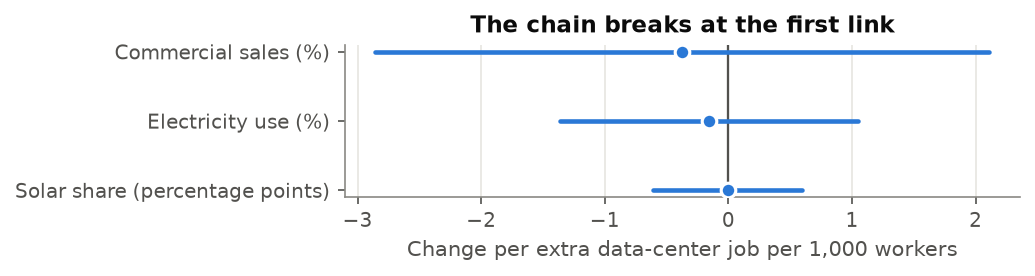

**In plain English.** The first domino doesn't fall in our data: across states, data-center jobs aren't associated with more electricity use, except in Virginia and Texas. And at the end of the chain, solar shows no association at all (p = 0.984).

**Why the hypothesis could still be true but invisible here.**
- **Timing.** Most data-center power demand arrives after 2022, and much of it after our data end in 2025. Georgia Power's commitments alone went from 3,600 MW (megawatts) to 15,600 MW between October 2023 and June 2026.
- **Purchases across state lines.** Tech companies often buy solar power from projects in other states. Our outcomes count solar where it's built, not where it's bought.
- **Planned, not built.** Much of the response is still in plans and interconnection queues, which our capacity data (built plants only) don't show.
- **National effects.** If data-center demand lowers solar costs or raises solar build-out everywhere, year effects absorb it, and state comparisons can't see it.

**What would test it better:** interconnection queue data by state (projects waiting to connect, such as LBNL (Lawrence Berkeley National Laboratory)'s *Queued Up*); utility resource plans and their stated reasons; an event study around 2022 comparing states before and after large data-center announcements; and data-center megawatts by state instead of jobs.

In [30]:
L.section(7, "Does data-center demand drive more solar? A team hypothesis")
md("""The hypothesis is a chain with three links: **data-center growth → more electricity demand → utilities add capacity → more of that capacity is solar.** If all three links hold, states with faster data-center growth should add more solar. We test each link with the H1 design ($y_{st} = \\beta AI_{s,t-1} + \\text{controls} + \\alpha_s + \\delta_t + \\varepsilon_{st}$). **Analogy:** a row of dominoes falls only if every domino hits the next. **"Yes"** would be a clearly positive association at every link, with clean timing.""")
L1 = "ext_impact_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_sales_com_pc_50s"
T(["Link", "What we measured", "Coefficient", "p-value", "Reading"], [
 ["1. Data centers to demand", "Commercial electricity sales per person (log)", est(IMP, tag=L1), p(IMP, tag=L1), "Not in pooled data; only Virginia and Texas"],
 ["1. Data centers to demand", "Total electricity use per person (log, H1)", est(H1C, tag=h1('ln_ec')), p(H1C, tag=h1('ln_ec')), "No association"],
 ["2. Demand to new capacity", "New renewable capacity, MW (H1)", est(H1X, tag=NRW), p(H1X, tag=NRW), "Positive in MW, but not per 1,000 MW, and the lead is positive too"],
 ["2. Demand to new capacity", "Gas added per 1,000 MW", est(IMP, tag=itg('add_gas_per1000')), p(IMP, tag=itg('add_gas_per1000')), f"Fails multiple testing (q = {v(IMP, 'qval', dec=3, tag=itg('add_gas_per1000'))})"],
 ["3. Capacity to solar", "Solar added per 1,000 MW", est(BT, tag='ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_add_solar_per1000_50s'), p(BT, tag='ext_bytype_twfe_ai518210_lag1_ctrl4_w9901_cl-state_add_solar_per1000_50s'), "No association"],
 ["3. Capacity to solar", "Solar share of generation", est(BT, tag=SS), p(BT, tag=SS), "No association"],
], "Each link of the chain, with data-center jobs as the AI measure, 50 states, 2015-2025.")
fig, ax = plt.subplots(figsize=(7.0, 1.94))
chain = [("Commercial sales (%)", IMP, L1, 100), ("Electricity use (%)", H1C, h1("ln_ec"), 100), ("Solar share (percentage points)", BT, SS, 100)]
coefplot(ax, [c[0] for c in chain], [k * raw(src, "estimate", tag=t) for _, src, t, k in chain], [k * raw(src, "ci_lo", tag=t) for _, src, t, k in chain],
         [k * raw(src, "ci_hi", tag=t) for _, src, t, k in chain], unit="Change per extra data-center job per 1,000 workers")
ax.set_title("The chain breaks at the first link")
L.fig(fig, "Associations at the demand link and the solar link, with 95% intervals.")
md(f"""**In plain English.** The first domino doesn't fall in our data: across states, data-center jobs aren't associated with more electricity use, except in Virginia and Texas. And at the end of the chain, solar shows no association at all ({p(BT, tag=SS)}).

**Why the hypothesis could still be true but invisible here.**
- **Timing.** Most data-center power demand arrives after 2022, and much of it after our data end in 2025. Georgia Power's commitments alone went from {s(GFF, 'value', figure='Commitments, Oct 2023 to June 30, 2026')} between October 2023 and June 2026.
- **Purchases across state lines.** Tech companies often buy solar power from projects in other states. Our outcomes count solar where it's built, not where it's bought.
- **Planned, not built.** Much of the response is still in plans and interconnection queues, which our capacity data (built plants only) don't show.
- **National effects.** If data-center demand lowers solar costs or raises solar build-out everywhere, year effects absorb it, and state comparisons can't see it.

**What would test it better:** interconnection queue data by state (projects waiting to connect, such as LBNL's *Queued Up*); utility resource plans and their stated reasons; an event study around 2022 comparing states before and after large data-center announcements; and data-center megawatts by state instead of jobs.""")

# 8. Georgia

Georgia is a useful case: a fast-growing data-center market served mostly by one regulated utility, Georgia Power, whose plans are public through the Georgia PSC (Public Service Commission).

**AI (artificial intelligence) growth.** Georgia ranked 22 of 50 states in data-center jobs per 1,000 workers in 2015 and 2 in 2025; its rise over 2015-2024 ranks 2. On AI job postings it ranks only 25 in 2025, a reminder that the two AI measures capture different things.

**The solar boom.** Solar's share of Georgia's in-state generation rose from 0.1% in 2015 to 7.7% in 2025.

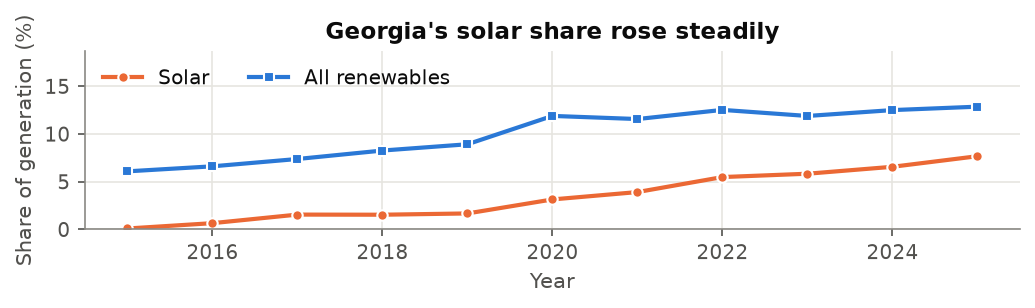

**What our estimates imply for Georgia.** Taking our national solar-share association and Georgia's actual rise in data-center jobs, the association could account for at most 25% of Georgia's solar-share rise, using the end of the confidence interval most favorable to AI, and the point estimate has the opposite sign. Georgia's solar boom is associated with falling costs, tax credits and the utility's plans, not with anything our data link to AI.

Item,Figure,Document,PDF (Portable Document Format) page
"2025 IRP summary: load growth, next six years","about 8,500 MW (megawatts)",IRP one-page summary,1
2025 IRP: renewable procurement,"up to 4,000 MW by 2035",IRP main document,67
2025 IRP: battery storage in progress,"more than 2,065 MW",IRP main document,10
"Commitments at the 2023 IRP Update, Oct 2023","3,600 MW","Large-load report, Q1 2026",8
"Commitments, June 30, 2026","15,600 MW across 32 customers","Large-load report, Q2 2026",5
"Commitments by winter 2028/2029, Q2 2026","8,700 MW","Large-load report, Q2 2026",5
"Total pipeline, Q2 2026","84,800 MW","Large-load report, Q2 2026",8


**Georgia Power's response.** The utility's 2025 IRP (Integrated Resource Plan) plans for about about 8,500 MW (megawatts) of load growth over six years, mostly from large customers such as data centers, and responds with a mix: renewable procurement of up to 4,000 MW by 2035 (PDF (Portable Document Format) page 67), battery storage, new gas turbines and extended coal units. So the utility's response to data-center demand includes solar, but not only solar.

In [31]:
L.section(8, "Georgia")
md(f"""Georgia is a useful case: a fast-growing data-center market served mostly by one regulated utility, Georgia Power, whose plans are public through the Georgia PSC.

**AI growth.** Georgia ranked {n(GAI, 'jobs_rank_of_50', item='AI level, 2015')} of 50 states in data-center jobs per 1,000 workers in 2015 and {n(GAI, 'jobs_rank_of_50', item='AI level, 2025')} in 2025; its rise over 2015-2024 ranks {n(GAI, 'jobs_rank_of_50', item='AI change (jobs 2015-2024; postings 2018-2024)')}. On AI job postings it ranks only {n(GAI, 'postings_rank_of_50', item='AI level, 2025')} in 2025, a reminder that the two AI measures capture different things.

**The solar boom.** Solar's share of Georgia's in-state generation rose from {v(GMX, 'share_solar', scale=100, dec=1, year=2015)}% in 2015 to {v(GMX, 'share_solar', scale=100, dec=1, year=2025)}% in 2025.""")
g = tbl(GMX)
fig, ax = plt.subplots(figsize=(7.0, 2.11))
ax.plot(g.year, 100 * g.share_solar, "-o", color=ORANGE, lw=2, ms=5, mec="white", label="Solar")
ax.plot(g.year, 100 * g.renew_share, "-s", color=BLUE, lw=2, ms=5, mec="white", label="All renewables")
ax.set_ylim(0, 1.45 * 100 * g.renew_share.max()); ax.set_xlabel("Year"); ax.set_ylabel("Share of generation (%)"); ax.legend(loc="upper left", ncol=2)
ax.set_title("Georgia's solar share rose steadily")
L.fig(fig, "Solar and total renewable share of Georgia's in-state utility-scale generation.")
md(f"""**What our estimates imply for Georgia.** Taking our national solar-share association and Georgia's actual rise in data-center jobs, the association could account for at most {v(GIM, 'at_most_share_of_actual', scale=100, sig=2, tag=SS)}% of Georgia's solar-share rise, using the end of the confidence interval most favorable to AI, and the point estimate has the opposite sign. Georgia's solar boom is associated with falling costs, tax credits and the utility's plans, not with anything our data link to AI.""")
irp = [("2025 IRP summary: load growth, next six years", "IRP one-page summary"), ("2025 IRP: renewable procurement", "IRP main document"),
       ("2025 IRP: battery storage in progress", "IRP main document"), ("Commitments at the 2023 IRP Update, Oct 2023", "Large-load report, Q1 2026"),
       ("Commitments, June 30, 2026", "Large-load report, Q2 2026"), ("Commitments by winter 2028/2029, Q2 2026", "Large-load report, Q2 2026"),
       ("Total pipeline, Q2 2026", "Large-load report, Q2 2026")]
T(["Item", "Figure", "Document", "PDF page"], [[f, s(GFF, "value", figure=f), d, s(GFF, "pdf_page", figure=f)] for f, d in irp],
  "Georgia Power's IRP response and large-load reporting, as filed with the Georgia PSC (Dockets 56002 and 55378).",
  "These are the utility's own figures, quoted from the filings; they aren't our estimates.")
md(f"""**Georgia Power's response.** The utility's 2025 IRP plans for about {s(GFF, 'value', figure='2025 IRP summary: load growth, next six years')} of load growth over six years, mostly from large customers such as data centers, and responds with a mix: renewable procurement of {s(GFF, 'value', figure='2025 IRP: renewable procurement')} (PDF page {s(GFF, 'pdf_page', figure='2025 IRP: renewable procurement')}), battery storage, new gas turbines and extended coal units. So the utility's response to data-center demand includes solar, but not only solar.""")

## The solar cost projection to 2035

**The question.** If solar keeps getting cheaper as the world builds more of it, what would new Georgia solar cost in 2035?
$$C_{2035} = C_{2025} \times \left(\frac{X_{2035}}{X_{2025}}\right)^{b}, \qquad b = \log_2(1 - LR)$$

Symbol,Plain meaning
$C$,"LCOE (levelized cost of energy) of new utility-scale solar in Georgia, 2025 dollars per MWh (megawatt-hours), without tax credits"
$X$,"Cumulative global solar PV (photovoltaic) capacity, from IEA (International Energy Agency) WEO (World Energy Outlook) 2025 scenario paths"
$LR$,Learning rate: the cost drop for each doubling of cumulative capacity
$b$,"The curve's slope, set by the learning rate"


**Analogy:** TVs got cheaper as factories made more of them; the same pattern has held for solar panels. **"Yes"** in this context means only that the arithmetic gives a lower cost; this is a projection under assumptions, not a test or a forecast of ours.

Learning rate,Capacity path,2025,2035,Change 2025-2035 (%)
12%,Low,61.44,50.40,−18.0
24% (main),Low,58.82,38.45,−34.6
24% (main),Central,58.82,37.06,−37.0
24% (main),High,58.82,32.33,−45.0
45% (2014-2020 epoch),High,53.45,14.51,−72.9


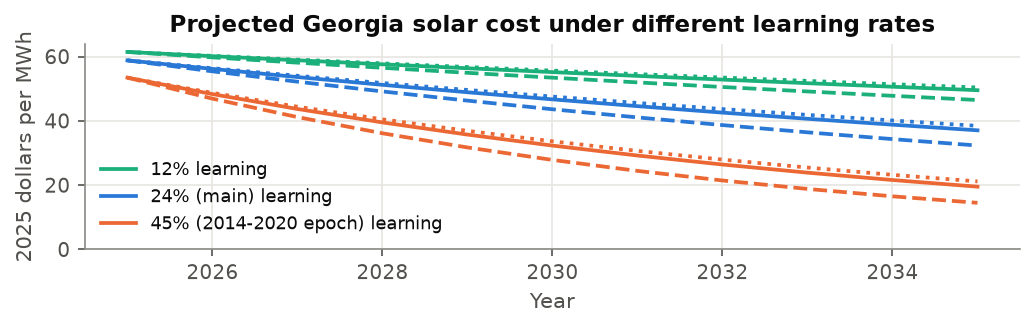

**In plain English.** Starting from Georgia's capacity-weighted LCOE (levelized cost of energy) of 63.81 dollars per MWh (megawatt-hours) for 17 recent projects, a 24% learning rate on the central path implies about 37.06 dollars per MWh in 2035; across all twelve combinations, the range is 14.51 to 50.40. These aren't forecasts of ours and contain no AI variable. One warning: national solar costs actually rose from 50.53 to 61.45 dollars per MWh between 2022 and 2025, so the curve assumes costs resume falling.

In [32]:
md("## The solar cost projection to 2035")
md(r"""**The question.** If solar keeps getting cheaper as the world builds more of it, what would new Georgia solar cost in 2035?
$$C_{2035} = C_{2025} \times \left(\frac{X_{2035}}{X_{2025}}\right)^{b}, \qquad b = \log_2(1 - LR)$$""")
T(["Symbol", "Plain meaning"], [
 ["$C$", "LCOE of new utility-scale solar in Georgia, 2025 dollars per MWh, without tax credits"],
 ["$X$", "Cumulative global solar PV capacity, from IEA WEO 2025 scenario paths"],
 ["$LR$", "Learning rate: the cost drop for each doubling of cumulative capacity"],
 ["$b$", "The curve's slope, set by the learning rate"],
], "Symbols in the learning-curve projection.")
md("""**Analogy:** TVs got cheaper as factories made more of them; the same pattern has held for solar panels. **"Yes"** in this context means only that the arithmetic gives a lower cost; this is a projection under assumptions, not a test or a forecast of ours.""")
T(["Learning rate", "Capacity path", "2025", "2035", "Change 2025-2035 (%)"],
  [[lr, pth_, v(GPT, "2025", dec=2, lr_label=lr, path=pth_), v(GPT, "2035", dec=2, lr_label=lr, path=pth_), v(GPT, "change_2025_2035_pct", dec=1, lr_label=lr, path=pth_)]
   for lr, pth_ in [("12%", "Low"), ("24% (main)", "Low"), ("24% (main)", "Central"), ("24% (main)", "High"), ("45% (2014-2020 epoch)", "High")]],
  "Georgia solar LCOE, 2025 dollars per MWh. Paths from IEA WEO 2025, Annex A: Low = Current Policies (Table A.3a, p. 417), Central = Stated Policies (Table A.3b, p. 423), High = Net Zero Emissions by 2050 (Table A.3c, p. 429).")
gl = tbl(GPL)
fig, ax = plt.subplots(figsize=(7.0, 2.29))
for lr, c in [("12%", AQUA), ("24% (main)", BLUE), ("45% (2014-2020 epoch)", ORANGE)]:
    for pth_, ls in [("Low", ":"), ("Central", "-"), ("High", "--")]:
        d = gl[(gl.lr_label == lr) & (gl.path == pth_)]
        ax.plot(d.year, d.lcoe_2025usd_mwh, color=c, ls=ls, lw=1.8, label=f"{lr} learning" if pth_ == "Central" else None)
ax.set_xlabel("Year"); ax.set_ylabel("2025 dollars per MWh"); ax.set_ylim(bottom=0); ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Projected Georgia solar cost under different learning rates")
L.fig(fig, "Learning-curve arithmetic for Georgia solar. Solid: central capacity path; dotted: low; dashed: high.")
md(f"""**In plain English.** Starting from Georgia's capacity-weighted LCOE of {v(GBC, 'lcoe_capacity_weighted', dec=2, area='Georgia')} dollars per MWh for {n(GBC, 'n_projects', area='Georgia')} recent projects, a 24% learning rate on the central path implies about {v(GPT, '2035', dec=2, lr_label='24% (main)', path='Central')} dollars per MWh in 2035; across all twelve combinations, the range is {v(GPT, '2035', dec=2, lr_label='45% (2014-2020 epoch)', path='High')} to {v(GPT, '2035', dec=2, lr_label='12%', path='Low')}. These aren't forecasts of ours and contain no AI variable. One warning: national solar costs actually rose from {v(NLC, 'lcoe', dec=2, year=2022)} to {v(NLC, 'lcoe', dec=2, year=2025)} dollars per MWh between 2022 and 2025, so the curve assumes costs resume falling.""")

In [33]:
L.section(9, "Limitations")
md(f"""- **Jobs aren't megawatts.** Data-center jobs in NAICS 518210 include general data processing and web hosting, not only AI, and a data center's power use isn't proportional to its staff. A highly automated facility can use a lot of electricity with few workers.
- **Little variation within states.** Our models compare each state with itself, and data-center jobs move only modestly within a state (one SD is {v(RO, 'sd_ai', sig=3, tag='rob_base_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025')} jobs per 1,000 workers). That limits how precisely any effect can be measured.
- **Timing.** Our data end in 2025, before most of the data-center build-out now being planned.
- **No strong instrument.** Our only instrument is weak, so we can't separate cause from selection.
- **Utility-scale only.** EIA state generation misses rooftop solar.
- **The EIA accounting change** affects every SEDS-based renewable number, and results differ by data version.
- **Weather** enters one check only, for the 48 contiguous states.
- **Georgia** is regulated, so its utility's behavior may not generalize to states with competitive power markets.
- **Pending:** the rerun of Fang's model with GDP in chained 2012 dollars (section 5.2).""")

# 9. Limitations

- **Jobs aren't megawatts.** Data-center jobs in NAICS 518210 (North American Industry Classification System code 518210, Computing Infrastructure Providers, Data Processing, Web Hosting) include general data processing and web hosting, not only AI (artificial intelligence), and a data center's power use isn't proportional to its staff. A highly automated facility can use a lot of electricity with few workers.
- **Little variation within states.** Our models compare each state with itself, and data-center jobs move only modestly within a state (one SD (standard deviation) is 0.521 jobs per 1,000 workers). That limits how precisely any effect can be measured.
- **Timing.** Our data end in 2025, before most of the data-center build-out now being planned.
- **No strong instrument.** Our only instrument is weak, so we can't separate cause from selection.
- **Utility-scale only.** EIA (U.S. Energy Information Administration) state generation misses rooftop solar.
- **The EIA accounting change** affects every SEDS (State Energy Data System)-based renewable number, and results differ by data version.
- **Weather** enters one check only, for the 48 contiguous states.
- **Georgia** is regulated, so its utility's behavior may not generalize to states with competitive power markets.
- **Pending:** the rerun of Fang's model with GDP (gross domestic product) in chained 2012 dollars (section 5.2).

In [34]:
L.section(10, "FAQ")
md(f"""**Is a null result a failure?** No. A precise null rules things out. Our intervals exclude, for example, a 1% rise in electricity use per person from a typical swing in data-center jobs. Knowing what *didn't* happen in 2015-2025 is useful when people predict what AI will do to the grid.

**Why year fixed effects?** Because 2015-2025 saw big national changes: tax credits, falling solar prices, COVID. Without year effects, any state series that rose over time would look associated with renewables. Section 5.4 shows exactly this: pet-care jobs "predict" renewables in a model without year effects.

**Why didn't we get Fang's result?** Mostly the data version and the missing year effects. On the EIA data Fang used, we get most of their number back; with year effects, a lag and a longer sample, it isn't positive.

**Why so many data sources?** No agency measures AI, electricity and policy together. Each source answers one piece, and each is the standard source for its piece.

**Could AI still matter?** Yes. Our results describe 2015-2025 and data-center *jobs*. The data-center build-out now under way is far larger: Georgia Power's large-load pipeline alone is {s(GFF, 'value', figure='Total pipeline, Q2 2026')}. Megawatt-based data and a few more years could show what jobs can't.""")

# 10. FAQ (frequently asked questions)

**Is a null result a failure?** No. A precise null rules things out. Our intervals exclude, for example, a 1% rise in electricity use per person from a typical swing in data-center jobs. Knowing what *didn't* happen in 2015-2025 is useful when people predict what AI (artificial intelligence) will do to the grid.

**Why year fixed effects?** Because 2015-2025 saw big national changes: tax credits, falling solar prices, COVID. Without year effects, any state series that rose over time would look associated with renewables. Section 5.4 shows exactly this: pet-care jobs "predict" renewables in a model without year effects.

**Why didn't we get Fang's result?** Mostly the data version and the missing year effects. On the EIA (U.S. Energy Information Administration) data Fang used, we get most of their number back; with year effects, a lag and a longer sample, it isn't positive.

**Why so many data sources?** No agency measures AI, electricity and policy together. Each source answers one piece, and each is the standard source for its piece.

**Could AI still matter?** Yes. Our results describe 2015-2025 and data-center *jobs*. The data-center build-out now under way is far larger: Georgia Power's large-load pipeline alone is 84,800 MW (megawatts). Megawatt-based data and a few more years could show what jobs can't.

In [35]:
L.section(11, "Glossary")
GDESC = {
 "AI": "Computer systems that perform tasks such as prediction and language; here measured through data-center jobs or AI job postings.",
 "ACS": "The Census Bureau's annual household survey; we use its broadband table.",
 "BEA": "The federal agency that publishes state GDP, income and population estimates.",
 "BLS": "The federal agency that counts jobs and wages.",
 "BTOS": "A Census Bureau survey that asks firms, among other things, whether they use AI.",
 "Btu": "A unit of energy; EIA SEDS reports energy in billions of them.",
 "CC BY": "A license that allows reuse with credit to the source.",
 "CDD": "A measure of how much cooling a year needed: degrees above 65°F, summed over days.",
 "CES": "A state mandate like an RPS that also counts other low-carbon sources such as nuclear.",
 "CO2": "The main greenhouse gas from burning fossil fuels.",
 "CRS": "The research arm of Congress; its reports document tax-credit rules.",
 "DC": "Washington, D.C., included in Fang's sample and dropped from ours.",
 "EIA": "The federal statistical agency for energy; source of our electricity and SEDS data.",
 "EPU": "A news-based index of economic policy uncertainty, by state, from Baker, Davis and Levy.",
 "FAQ": "Common questions with short answers.",
 "GDP": "The value of everything a state's economy produces in a year.",
 "GW": "A thousand megawatts.",
 "HDD": "A measure of how much heating a year needed: degrees below 65°F, summed over days.",
 "IEA": "An intergovernmental energy agency; its World Energy Outlook supplies our solar capacity paths.",
 "IRENA": "An intergovernmental agency that publishes renewable capacity statistics.",
 "IRP": "A utility's long-term plan for meeting demand, filed with its regulator.",
 "ITC": "A federal tax credit worth a share of the cost of a solar or other clean-energy project.",
 "IV": "A method that uses an outside source of variation to get closer to cause and effect.",
 "kWh": "A unit of electricity; prices are quoted in cents per kilowatt-hour.",
 "LBNL": "A national laboratory that publishes data on renewable costs and state renewable mandates.",
 "LCOE": "The average cost per MWh of building and running a power plant over its life.",
 "MW": "A unit of power plant capacity: a million watts.",
 "MWh": "A unit of electricity: one megawatt for one hour.",
 "NAICS 518210": "The industry code for data centers, data processing and web hosting; our AI measure counts its private jobs.",
 "NCSES": "The part of NSF that publishes science and engineering statistics.",
 "NOAA": "The federal agency for weather and climate data; source of degree days.",
 "NSF": "The federal agency that funds research and publishes R&D statistics.",
 "OEWS": "A BLS survey of jobs and wages by occupation; we use research scientists.",
 "OLS": "The standard regression method that fits a line by minimizing squared errors.",
 "OWID": "A website that republishes research data, including global solar capacity.",
 "PDF": "A document file format; we cite filings by their PDF page.",
 "PSC": "The state regulator that approves a utility's plans and rates.",
 "PTC": "A federal tax credit paid per MWh of electricity from wind and some other sources.",
 "PV": "Solar panels that turn sunlight directly into electricity.",
 "QCEW": "BLS's near-complete count of jobs and wages by industry and state.",
 "R&D": "Spending on research and development.",
 "RFP": "A utility's call for bids to build or supply new power.",
 "RPS": "A state law requiring a minimum share of electricity from renewables.",
 "SD": "A measure of typical spread around the average.",
 "SDM": "A spatial model with both neighbors' outcomes and neighbors' AI.",
 "SEDS": "EIA's state-level estimates of energy production, use and prices for every fuel.",
 "SLX": "A spatial model with neighbors' AI on the right-hand side.",
 "TWh": "A billion kilowatt-hours.",
 "USPTO": "The federal agency that grants patents; its AI patent data were downloaded and not used.",
 "WEO": "The IEA's annual report with scenario paths for energy to 2050.",
}
gl_terms = [(f"{k} ({ACRONYMS[k]})", GDESC[k]) for k in ACRONYMS if k in GDESC]
terms = gl_terms + [
 ("Association", "Two things moving together. Not proof that one causes the other."),
 ("Benjamini-Hochberg q-value", "A p-value adjusted for running many tests at once; we require q below 0.10."),
 ("Clustered standard errors", "Uncertainty estimates that treat a state's years as related, not independent."),
 ("Coefficient", "The slope: how much the outcome changes per unit of AI, other things fixed."),
 ("Confidence interval", "The range of values the data can't rule out, at 95% confidence."),
 ("Control variable", "Something held fixed in the comparison, such as income or electricity price."),
 ("Direct, indirect and total effects", "In spatial models: a state's own association, the spillover from other states, and their sum."),
 ("Elasticity", "Percent change in one thing per 1% change in another."),
 ("Fixed effects", "Terms that remove each state's permanent level (state effects) or each year's nationwide level (year effects)."),
 ("Lead (placebo) test", "Using next year's AI to check whether the timing makes sense."),
 ("Learning rate", "The cost drop for each doubling of cumulative production."),
 ("Lind-Mehlum test", "A test for a real curve: the slope must be clearly positive at one end and clearly negative at the other."),
 ("Mediation", "Testing whether an association runs through a third variable (a channel)."),
 ("Moran's I", "A measure of whether neighboring states have similar values."),
 ("p-value", "The chance of a result at least this far from zero if the true value were zero."),
 ("Panel data", "The same units (states) observed over many years."),
 ("Percentage point", "The unit for differences between percentages: 10% to 12% is 2 percentage points."),
 ("Placebo industry", "An industry unrelated to energy, used to check whether a model detects trends instead of AI."),
 ("Shift-share instrument", "A predicted value built from a state's starting share times national growth."),
 ("Winsorizing", "Capping extreme values at the 1st and 99th percentiles so a few outliers can't dominate."),
]
terms = sorted(terms, key=lambda x: x[0].lower())
L.deflist(terms, "Acronyms and technical terms, A to Z.")

# 11. Glossary

In [36]:
ck, unl = L.check()
display(HTML(f"<p class='tnote'>Number check: {len(ck)} numbers traced to result files; {int((ck.status == 'ok').sum())} match their source and appear in the text; {len(unl)} untraced decimal numbers. Details: results/2026-11-09/explained/number_check.csv.</p>"))